# 🌧️ Rainfall Forecasting — End-to-End Time Series Project
**Project:** PRAICP-1004 · Rainfall Time Series (Changing Climate Station, Singapore)
**Role:** AI Engineer

## 1. Business Case
The National Environment Agency (NEA) publishes monthly rainfall statistics recorded at the **Changi Climate Station**.
Accurate rainfall forecasts help with **water-resource planning, drainage/flood preparedness, outdoor-event and construction scheduling, and aviation operations**.

## 2. Project Goal
Build a **time-series forecasting model** that predicts **monthly total rainfall (mm)** for the coming months, and select the best model objectively.

## 3. Data (3 files, same station, monthly, 1982-01 → 2020-06)
| File | Column | Meaning |
|---|---|---|
| `rainfall-monthly-total.csv` | `total_rainfall` | Total rainfall in the month (mm) — **forecasting target** |
| `rainfall-monthly-number-of-rain-days.csv` | `no_of_rainy_days` | Days with ≥ 0.2 mm rain |
| `rainfall-monthly-highest-daily-total.csv` | `maximum_rainfall_in_a_day` | Wettest single day of the month (mm) |

## 4. Roadmap
| Step | What we do |
|---|---|
| 1 | Load, merge, audit the data (continuity, consistency, missing values) |
| 2 | **EDA** – distribution, outliers, trend, seasonality, decomposition, stationarity tests, ACF/PACF, variable relationships |
| 3 | Chronological **train / test split** + **rolling-origin cross-validation** (no shuffling, no leakage) |
| 4 | Models, **each one built to fix a weakness of the previous**: baselines → Holt-Winters → SARIMA → Harmonic regression → ML on lag features |
| 5 | Compare all models (CV + hold-out test), pick the best, check residuals |
| 6 | Re-fit best model on all data, forecast the future with prediction intervals |
| 7 | Save the model + metadata, reload it and forecast (deployment check) |

> Each code cell is followed by an **💡 Insight** cell that interprets the real output of that cell and states the decision it leads to.

## 1. Setup & Imports

In [4]:
import warnings, json, time, itertools, pathlib, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX

import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
SEED = 42
np.random.seed(SEED)
print("pandas", pd.__version__, "| statsmodels", sm.__version__)

pandas 2.2.3 | statsmodels 0.14.5


### 💡 Insight
- A fixed seed and a **chronological** evaluation design (set up below) make every model comparison reproducible and fair.
- `statsmodels` supplies the classical time-series tools (STL, ADF/KPSS, Holt-Winters, SARIMAX); `scikit-learn` supplies the ML models.

## 2. Load & Audit the Data

### 2.1 Load the three files and merge on month

In [5]:
DATA_DIR = pathlib.Path("/content/")

In [6]:
# Put the zip (or the extracted 'Data' folder) next to this notebook

FILES = {
    "rain_mm":      ("rainfall-monthly-total.csv",                 "total_rainfall"),
    "rain_days":    ("rainfall-monthly-number-of-rain-days.csv",   "no_of_rainy_days"),
    "max_daily_mm": ("rainfall-monthly-highest-daily-total.csv",   "maximum_rainfall_in_a_day"),
}
raw = {}
for new, (fn, col) in FILES.items():
    t = pd.read_csv(DATA_DIR / fn)
    raw[new] = t.rename(columns={col: new})
    print(f"{fn:45s} rows={len(t):4d} | nulls={int(t.isna().sum().sum())} | duplicated months={int(t['month'].duplicated().sum())}")

month_sets = [set(t["month"]) for t in raw.values()]
print("\nAll 3 files cover exactly the same months:", all(s == month_sets[0] for s in month_sets))

df = raw["rain_mm"].merge(raw["rain_days"], on="month").merge(raw["max_daily_mm"], on="month")
df["month"] = pd.to_datetime(df["month"])
df = df.set_index("month").sort_index().asfreq("MS")           # explicit monthly frequency
print("\nShape:", df.shape, "| from", df.index.min().date(), "to", df.index.max().date())
print("Months expected for a gap-free series:", (df.index.max().year - df.index.min().year) * 12 + df.index.max().month - df.index.min().month + 1)
print("Missing values after setting monthly frequency:\n", df.isna().sum().to_dict())
display(df.head()); display(df.tail())

FileNotFoundError: [Errno 2] No such file or directory: '\\content\\rainfall-monthly-total.csv'

### 💡 Insight
- All three files have **462 rows** (Jan 1982 → Jun 2020), no nulls, no duplicated months, and cover **exactly the same months**, so the merge is lossless.
- After forcing a monthly frequency the series is **gap-free (462 expected = 462 found)** — no imputation is needed, which is a precondition for SARIMA / Holt-Winters.
- The data ends in **June 2020**, so the 2020 year is incomplete (this matters for the annual-trend analysis later).

### 2.2 Logical-consistency checks between the three variables

In [ ]:
days_in_month = df.index.days_in_month
checks = {
    "rain_days > days in month":                    int((df.rain_days > days_in_month).sum()),
    "max daily rainfall > monthly total":           int((df.max_daily_mm > df.rain_mm + 1e-9).sum()),
    "rain_days == 0 but total > 0":                 int(((df.rain_days == 0) & (df.rain_mm > 0)).sum()),
    "rain_days > 0 but total == 0":                 int(((df.rain_days > 0) & (df.rain_mm == 0)).sum()),
    "months with total rainfall == 0":              int((df.rain_mm == 0).sum()),
    "negative values":                              int((df < 0).sum().sum()),
}
for k, v in checks.items():
    print(f"{k:45s}: {v}")

display(df.describe().round(2))
print("\nSkewness :", df.skew().round(2).to_dict())
print("Kurtosis :", df.kurt().round(2).to_dict())

rain_days > days in month                    : 0
max daily rainfall > monthly total           : 0
rain_days == 0 but total > 0                 : 0
rain_days > 0 but total == 0                 : 0
months with total rainfall == 0              : 0
negative values                              : 0


,rain_mm,rain_days,max_daily_mm
count,462.00,462.00,462.00
mean,176.24,13.96,52.36
std,113.30,4.95,35.69
min,0.20,1.00,0.20
25%,89.02,11.00,30.62
50%,158.45,14.00,43.45
75%,237.95,18.00,63.15
max,765.90,27.00,216.20



Skewness : {'rain_mm': 1.24, 'rain_days': -0.15, 'max_daily_mm': 1.86}
Kurtosis : {'rain_mm': 2.35, 'rain_days': -0.47, 'max_daily_mm': 4.35}


### 💡 Insight
- Every logical check returns **0**: rain days never exceed the days in the month, the wettest day is never larger than the monthly total, and there are no zero-rain or negative months. The data is clean and internally consistent.
- Target `rain_mm`: mean **176 mm**, median **158 mm**, range **0.2 – 765.9 mm**. Mean > median and skewness **1.24** → right-skewed (occasional very wet months).
- `max_daily_mm` is even more skewed (1.86; kurtosis 4.35): single extreme storm days exist. Because these extremes are internally consistent with the other columns, they are **real events, not data errors** — we keep them.

## 3. Exploratory Data Analysis (EDA)

### 3.1 The series over time

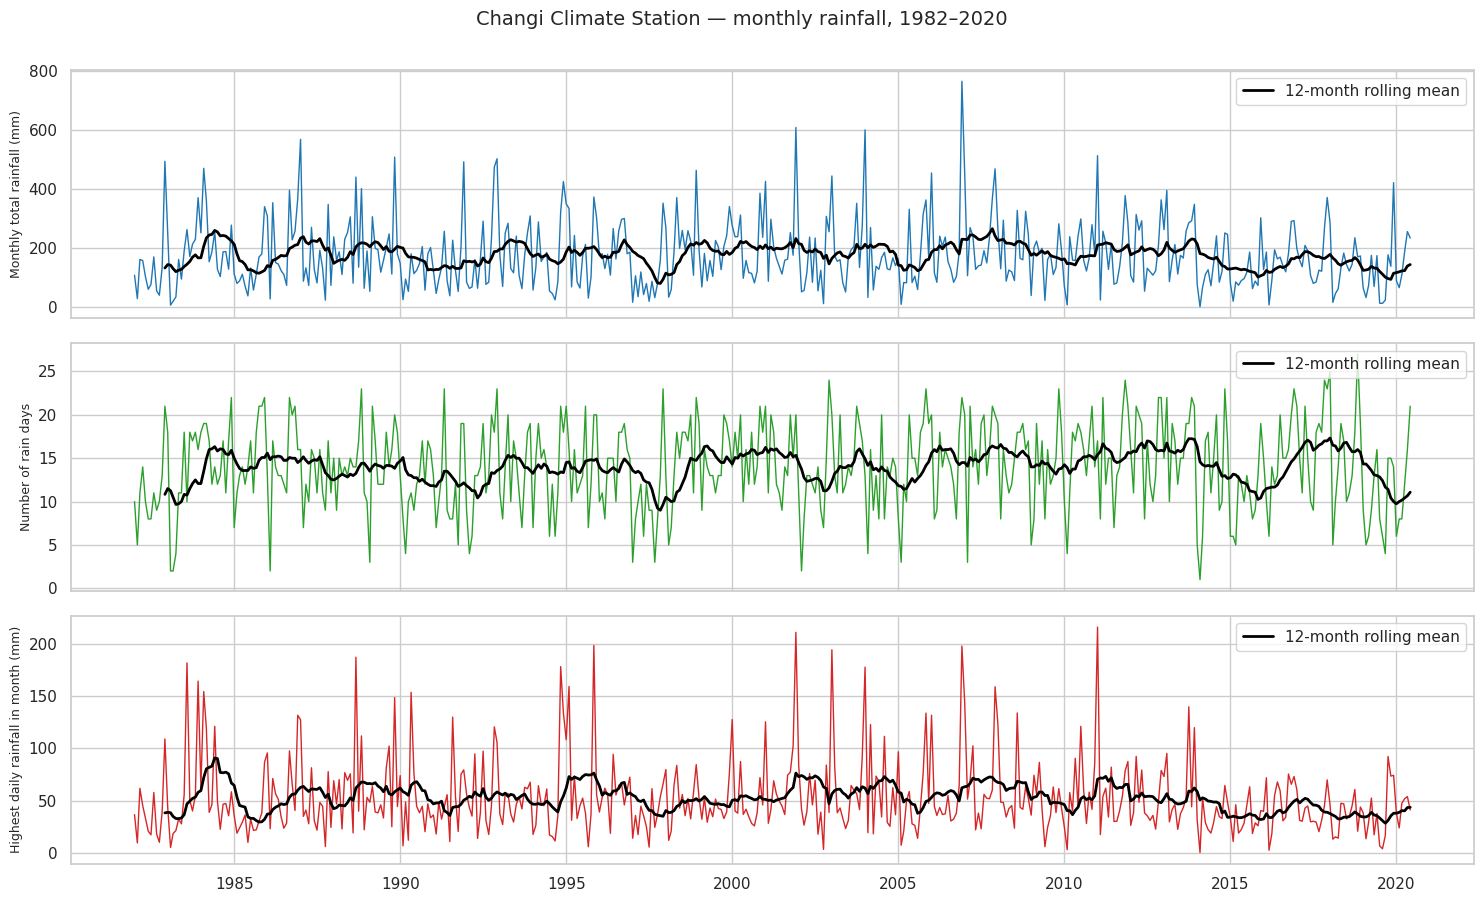

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for a, (c, col, lab) in zip(ax, [("rain_mm", "#1f77b4", "Monthly total rainfall (mm)"),
                                  ("rain_days", "#2ca02c", "Number of rain days"),
                                  ("max_daily_mm", "#d62728", "Highest daily rainfall in month (mm)")]):
    a.plot(df.index, df[c], color=col, lw=1)
    a.plot(df.index, df[c].rolling(12).mean(), color="black", lw=2, label="12-month rolling mean")
    a.set_ylabel(lab, fontsize=9); a.legend(loc="upper right")
plt.suptitle("Changi Climate Station — monthly rainfall, 1982–2020", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

### 💡 Insight
- All three series show a strong **repeating yearly cycle** with irregular spikes, and the 12-month rolling mean (black line) stays roughly flat around the long-run level → **no obvious long-term trend**.
- The three variables move together (more rain days → more total rain), but the spikes in `max_daily_mm` (up to **216 mm in one day**) show that a few violent storms can make up a large part of a month.
- Year-to-year variability is large: individual months range from almost nothing to several times the average.

### 3.2 Distribution of the target and outliers

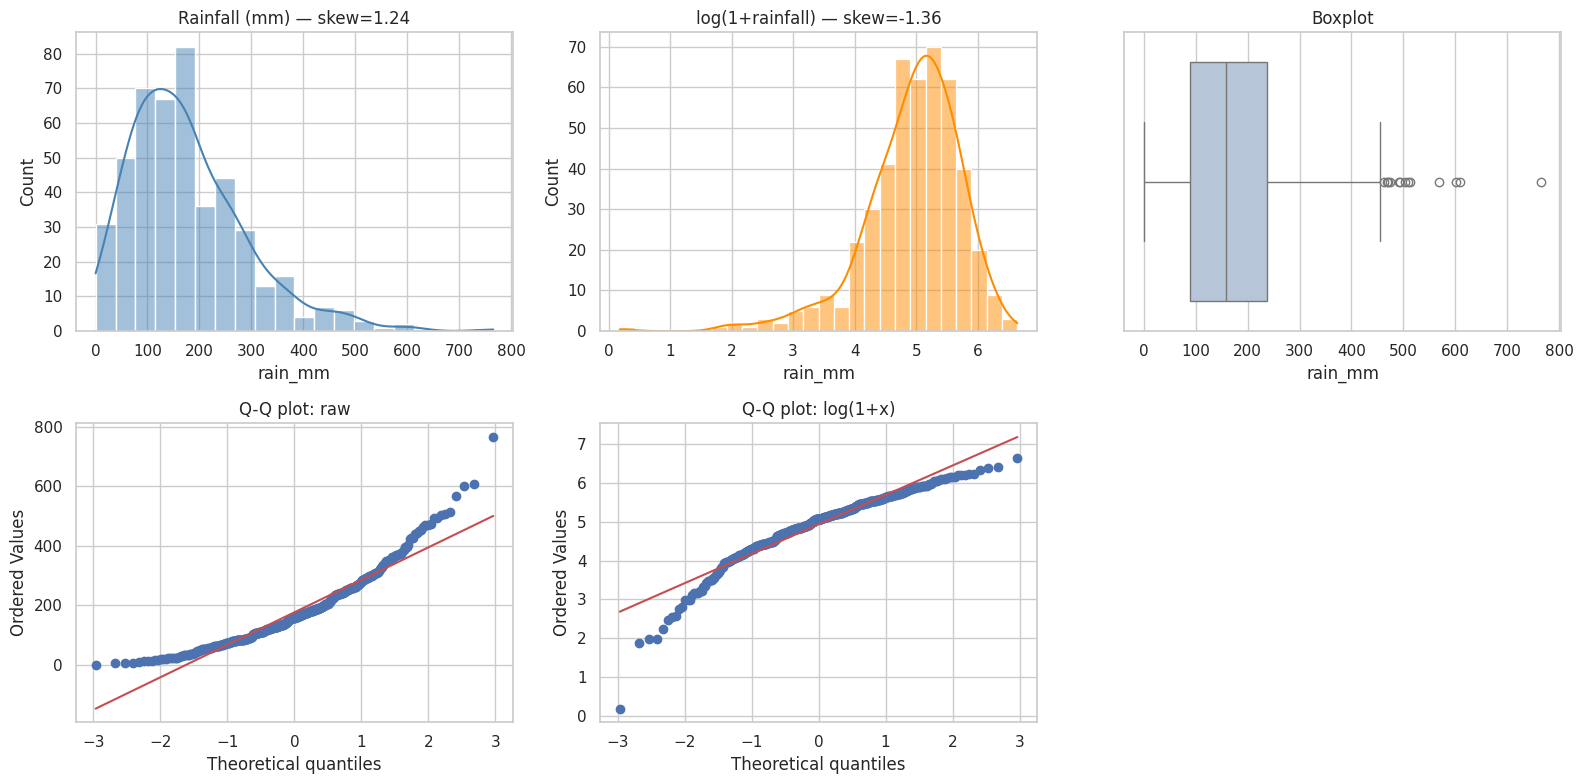

IQR upper fence = 461.3 mm → 13 months above it (2.8% of all months)

Top 10 wettest months:


,rain_mm,rain_days,max_daily_mm
month,,,
2006-12-01,765.9,22,198.0
2001-12-01,609.0,20,211.1
2004-01-01,600.9,13,177.8
1987-01-01,568.6,16,127.4
2011-01-01,513.2,17,216.2
1989-11-01,508.4,20,148.6
1992-12-01,502.7,23,105.7
1982-12-01,494.1,21,109.0
1991-12-01,492.3,19,79.4


Driest 5 months:


,rain_mm,rain_days,max_daily_mm
month,,,
2014-02-01,0.2,1,0.2
1983-02-01,5.6,2,5.1
2016-03-01,6.2,6,2.4
2010-02-01,6.3,4,2.9
2005-02-01,8.4,3,7.2


In [ ]:
y = df["rain_mm"]
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(y, kde=True, ax=ax[0, 0], color="steelblue");            ax[0, 0].set_title(f"Rainfall (mm) — skew={y.skew():.2f}")
sns.histplot(np.log1p(y), kde=True, ax=ax[0, 1], color="darkorange"); ax[0, 1].set_title(f"log(1+rainfall) — skew={np.log1p(y).skew():.2f}")
sns.boxplot(x=y, ax=ax[0, 2], color="lightsteelblue");                ax[0, 2].set_title("Boxplot")
stats.probplot(y, dist="norm", plot=ax[1, 0]);          ax[1, 0].set_title("Q-Q plot: raw")
stats.probplot(np.log1p(y), dist="norm", plot=ax[1, 1]); ax[1, 1].set_title("Q-Q plot: log(1+x)")
ax[1, 2].axis("off")
plt.tight_layout(); plt.show()

q1, q3 = y.quantile([.25, .75]); iqr = q3 - q1
upper = q3 + 1.5 * iqr
out = df[y > upper].sort_values("rain_mm", ascending=False)
print(f"IQR upper fence = {upper:.1f} mm → {len(out)} months above it ({len(out)/len(y):.1%} of all months)")
print("\nTop 10 wettest months:")
display(out.head(10))
print("Driest 5 months:")
display(df.sort_values("rain_mm").head(5))

### 💡 Insight
- Raw rainfall is **right-skewed (1.24)**; `log(1+x)` removes the long right tail but **over-corrects** to a skew of −1.36 (a few near-dry months now form a left tail). So log is a good variance stabiliser but not perfect — a Box-Cox/power transform is a possible refinement.
- **13 months (2.8 %)** exceed the IQR upper fence of 461 mm. The top ten are all in **November–January** (e.g. Dec 2006 = **765.9 mm** with 22 rain days and a 198 mm single day; Dec 2001 = 609 mm; Jan 2004 = 601 mm). Because they are consistent with the other variables they are genuine monsoon events → **kept, not removed** (removing them would make the model blind to the very months that matter most for flood planning).
- The driest month, **Feb 2014, recorded only 0.2 mm (1 rain day)**; the next driest are also Februaries/Marches → dry extremes are concentrated in Feb–Mar.

### 3.3 Seasonality — which months are wet and which are dry?

,mean,median,std,min,max,CV (std/mean)
Jan,226.0,193.9,152.8,15.4,600.9,0.68
Feb,104.7,69.2,107.0,0.2,470.4,1.02
Mar,160.3,132.5,103.2,6.2,361.3,0.64
Apr,153.0,157.0,67.7,33.6,311.6,0.44
May,165.8,157.5,75.3,41.6,370.8,0.45
Jun,134.3,118.3,65.7,21.8,265.8,0.49
Jul,146.3,142.4,72.5,12.2,305.4,0.50
Aug,147.1,152.4,70.5,11.8,327.3,0.48
Sep,145.7,125.2,93.2,22.8,440.4,0.64
Oct,161.4,162.8,82.7,10.8,351.4,0.51


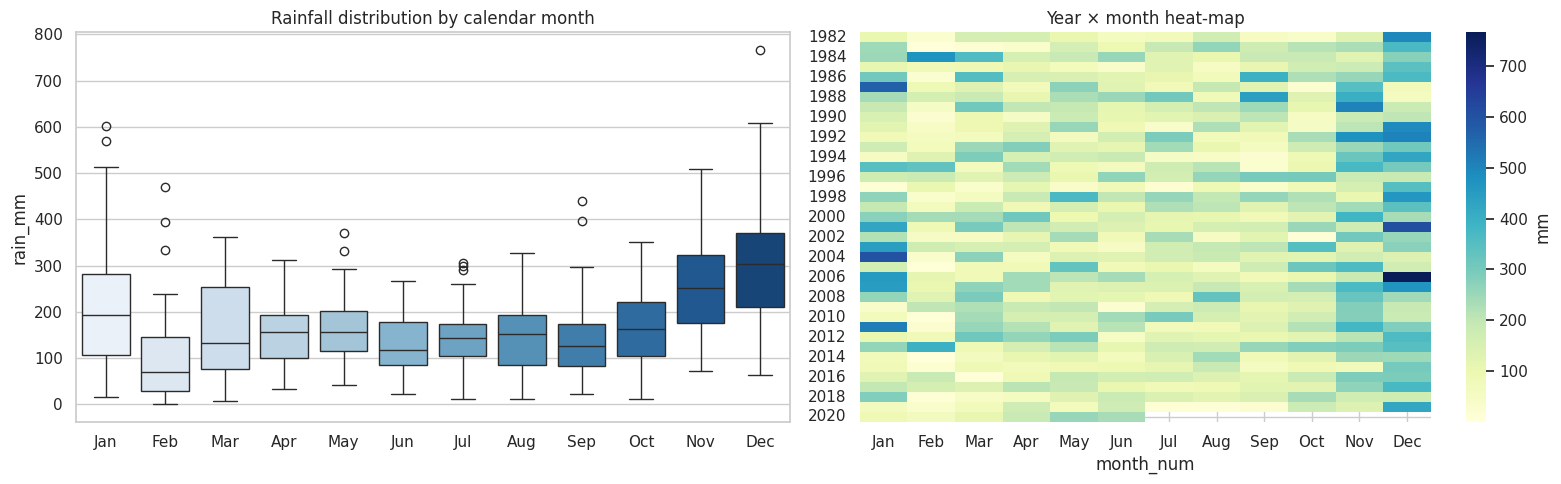

INSIGHT: wettest month on average = Dec (318 mm), driest = Feb (105 mm); ratio = 3.0×


In [ ]:
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
tmp = df.copy(); tmp["year"] = tmp.index.year; tmp["month_num"] = tmp.index.month

clim = tmp.groupby("month_num")["rain_mm"].agg(["mean", "median", "std", "min", "max"]).round(1)
clim["CV (std/mean)"] = (clim["std"] / clim["mean"]).round(2)
clim.index = month_names
display(clim)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=tmp, x="month_num", y="rain_mm", ax=ax[0], palette="Blues")
ax[0].set_xticklabels(month_names); ax[0].set_title("Rainfall distribution by calendar month"); ax[0].set_xlabel("")
pivot = tmp.pivot_table(index="year", columns="month_num", values="rain_mm")
sns.heatmap(pivot, cmap="YlGnBu", ax=ax[1], xticklabels=month_names, cbar_kws={"label": "mm"})
ax[1].set_title("Year × month heat-map"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

wettest, driest = clim["mean"].idxmax(), clim["mean"].idxmin()
print(f"INSIGHT: wettest month on average = {wettest} ({clim['mean'].max():.0f} mm), driest = {driest} ({clim['mean'].min():.0f} mm); "
      f"ratio = {clim['mean'].max()/clim['mean'].min():.1f}×")

### 💡 Insight
- A clear, repeatable **annual cycle**: **December is the wettest month (318 mm average) and February the driest (105 mm)** — a 3.0× difference. November (256 mm) and January (226 mm) are also wet; April–October are fairly even at roughly 135–165 mm.
- Variability is **not equal across months**: the coefficient of variation is about **0.4–0.5 in stable months but 1.02 for February and 0.68 for January** — i.e. the dry-season months are the least predictable relative to their level.
- The heat-map shows the Nov–Jan band is consistently darkest, but with large differences between years (some Decembers are far wetter than others) → the seasonal pattern is strong, yet each individual year deviates a lot. Seasonality must be in the model; it will not be enough on its own.

### 3.4 Long-term trend (annual totals)

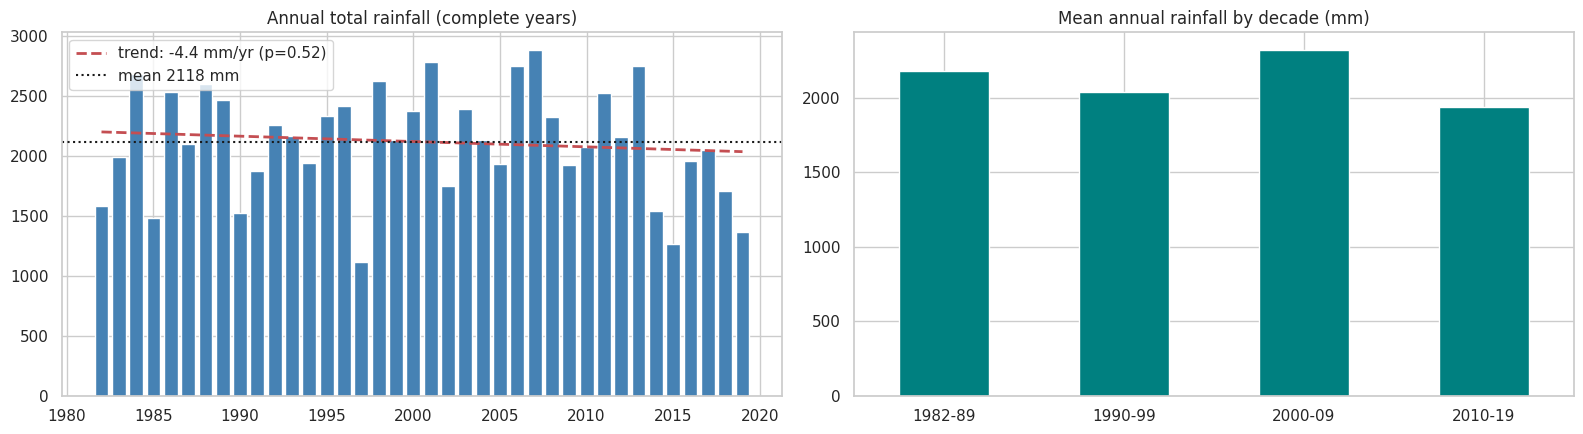

Linear trend: -4.45 mm/year, R²=0.012, p-value=0.515 | Spearman rho=-0.12, p=0.479
INSIGHT: NO statistically significant long-term trend at 5% level.


In [ ]:
annual = tmp[tmp.year < 2020].groupby("year")["rain_mm"].sum()       # 2020 is incomplete (Jan–Jun) → excluded
slope, intercept, r, p, se = stats.linregress(annual.index, annual.values)
rho, p_s = stats.spearmanr(annual.index, annual.values)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].bar(annual.index, annual.values, color="steelblue")
ax[0].plot(annual.index, intercept + slope * annual.index, "r--", lw=2, label=f"trend: {slope:+.1f} mm/yr (p={p:.2f})")
ax[0].axhline(annual.mean(), color="k", ls=":", label=f"mean {annual.mean():.0f} mm"); ax[0].legend(); ax[0].set_title("Annual total rainfall (complete years)")
decade = pd.cut(annual.index, [1981, 1989, 1999, 2009, 2019], labels=["1982-89", "1990-99", "2000-09", "2010-19"])
annual.groupby(decade).mean().round(0).plot(kind="bar", ax=ax[1], color="teal", rot=0); ax[1].set_title("Mean annual rainfall by decade (mm)")
plt.tight_layout(); plt.show()
print(f"Linear trend: {slope:+.2f} mm/year, R²={r**2:.3f}, p-value={p:.3f} | Spearman rho={rho:.2f}, p={p_s:.3f}")
print("INSIGHT:", "statistically significant trend." if p < 0.05 else "NO statistically significant long-term trend at 5% level.")

### 💡 Insight
- The fitted linear trend is **−4.5 mm/year, R² = 0.012, p = 0.52** (Spearman p = 0.48) → **no statistically significant long-term trend**. The incomplete 2020 was excluded so partial-year totals do not distort the result.
- Annual totals average **2 118 mm** but swing widely, from **1 119 mm (1997)** to **2 886 mm (2007)**. Decade means (2181 → 2040 → 2325 → 1939 mm) go up and down rather than in one direction; the lowest decade is 2010–19, but the swings are within normal variability.
- **Modelling decision:** no trend term / no first differencing is needed (d = 0). Note that the last few years are drier (2017: 2 046, 2018: 1 708, 2019: 1 368 mm) — this will show up later as a *bias* in every model's test forecasts.

### 3.5 STL decomposition: trend + seasonal + residual

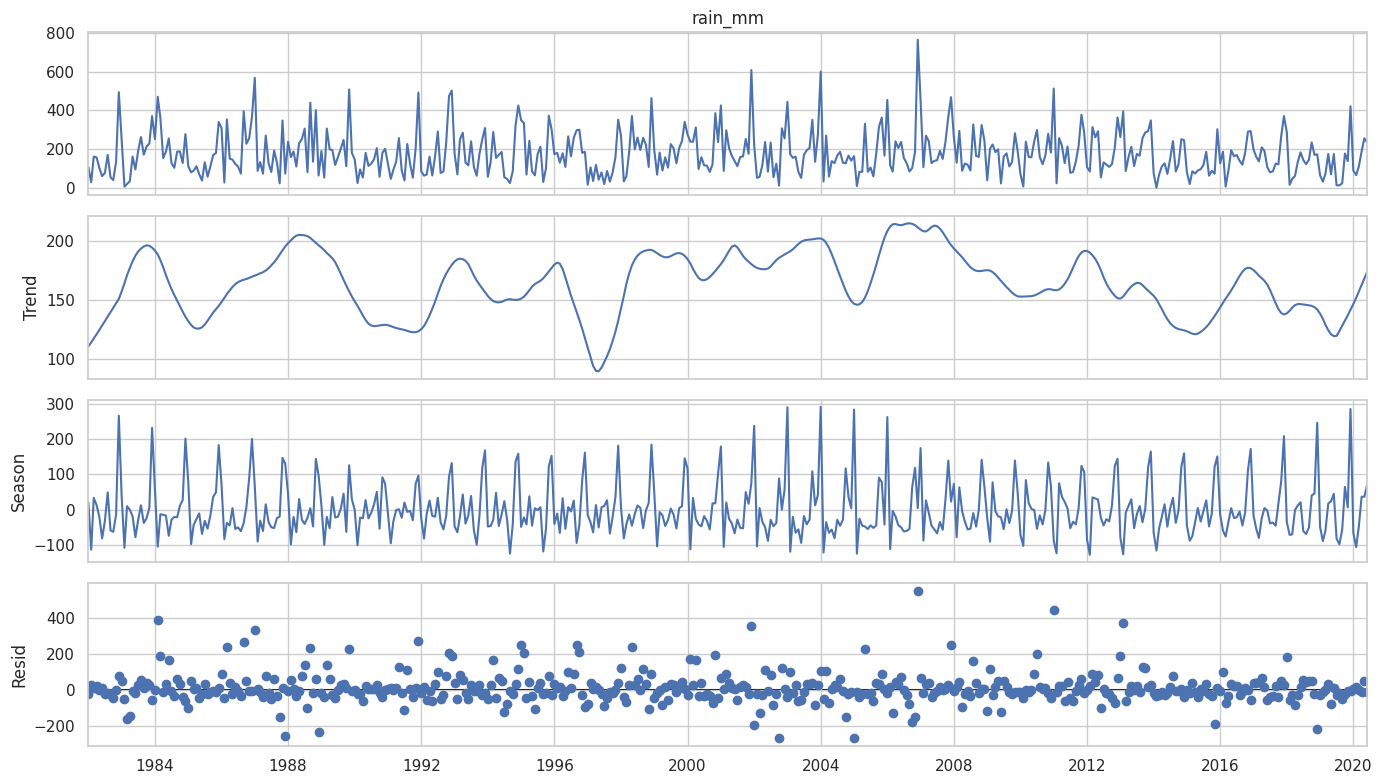

Strength of seasonality  Fs = 0.36  (0 = none, 1 = perfectly seasonal)
Strength of trend        Ft = 0.11
Share of total variance left in the residual (unpredictable noise) = 58.9%


In [ ]:
stl = STL(y, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(14, 8); plt.tight_layout(); plt.show()

Fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
Ft = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
share_resid = stl.resid.var() / y.var()
print(f"Strength of seasonality  Fs = {Fs:.2f}  (0 = none, 1 = perfectly seasonal)")
print(f"Strength of trend        Ft = {Ft:.2f}")
print(f"Share of total variance left in the residual (unpredictable noise) = {share_resid:.1%}")

### 💡 Insight
- **Seasonal strength Fs = 0.36**, **trend strength Ft = 0.11**: seasonality is real but moderate, and the trend component is almost negligible.
- **58.9 % of the variance is left in the STL residual** — the irregular, week-to-week weather noise that no calendar-based model can explain. This sets a **ceiling on forecast accuracy**: even a perfect seasonal model will still have large errors, so we should judge models by how much they improve over a simple baseline, not by expecting near-perfect fits.
- In-sample, the 12 calendar-month averages alone explain about 25 % of monthly variance (computed on the training years).

### 3.6 Variance behaviour — does the spread grow with the level?

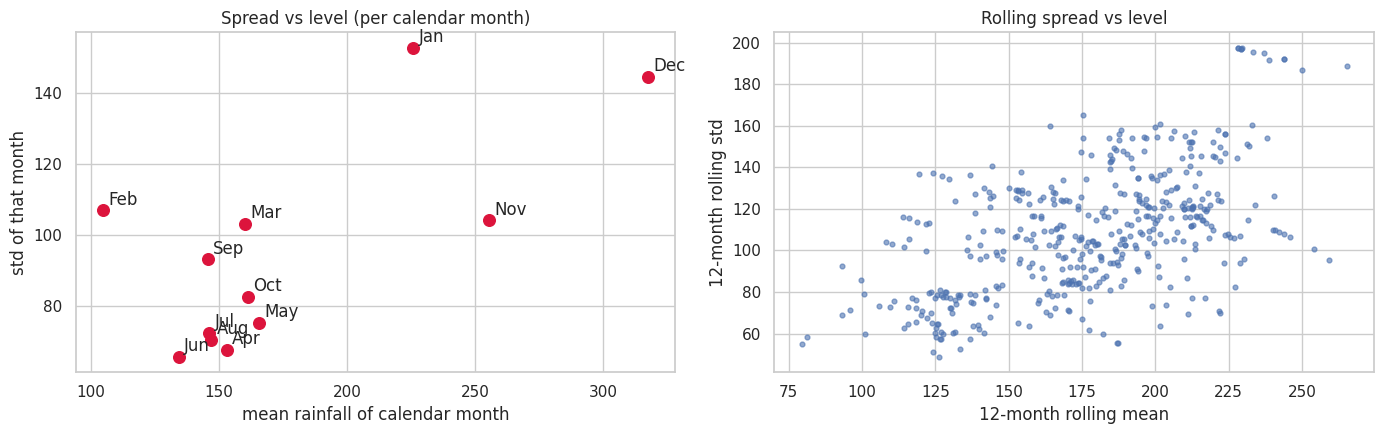

Correlation(mean, std) across calendar months = 0.69
Skewness raw = 1.24  →  after log(1+x) = -1.36


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
g = tmp.groupby("month_num")["rain_mm"].agg(["mean", "std"])
ax[0].scatter(g["mean"], g["std"], s=70, color="crimson")
for i, r_ in g.iterrows(): ax[0].annotate(month_names[i - 1], (r_["mean"], r_["std"]), xytext=(4, 4), textcoords="offset points")
ax[0].set_xlabel("mean rainfall of calendar month"); ax[0].set_ylabel("std of that month"); ax[0].set_title("Spread vs level (per calendar month)")
roll = pd.DataFrame({"mean": y.rolling(12).mean(), "std": y.rolling(12).std()}).dropna()
ax[1].scatter(roll["mean"], roll["std"], s=12, alpha=.6); ax[1].set_xlabel("12-month rolling mean"); ax[1].set_ylabel("12-month rolling std"); ax[1].set_title("Rolling spread vs level")
plt.tight_layout(); plt.show()
c = g["mean"].corr(g["std"])
print(f"Correlation(mean, std) across calendar months = {c:.2f}")
print(f"Skewness raw = {y.skew():.2f}  →  after log(1+x) = {np.log1p(y).skew():.2f}")

### 💡 Insight
- Spread grows with level: across calendar months, **corr(mean, std) = 0.69** — wetter months are also more variable (heteroscedasticity). Linear models with constant error variance would therefore be dominated by the wet months.
- A log transform stabilises this; it is also convenient because it guarantees **non-negative forecasts** after back-transforming. The skew moves from **1.24 → −1.36**, i.e. it slightly over-corrects, so we will test log-scale models **and** raw-scale models and let cross-validation decide.

### 3.7 Stationarity tests (ADF & KPSS)

In [ ]:
def stationarity(s, name):
    s = pd.Series(s).dropna()
    adf_stat, adf_p = adfuller(s, autolag="AIC")[:2]
    kp_stat, kp_p = kpss(s, regression="c", nlags="auto")[:2]
    verdict = ("stationary" if (adf_p < .05 and kp_p >= .05) else
               "non-stationary" if (adf_p >= .05 and kp_p < .05) else "conflicting / borderline")
    return {"series": name, "ADF stat": round(adf_stat, 2), "ADF p": round(adf_p, 4),
            "KPSS stat": round(kp_stat, 3), "KPSS p (capped .01–.1)": round(kp_p, 3), "verdict": verdict}

ylog = np.log1p(y)
tests = pd.DataFrame([
    stationarity(y, "raw rainfall"),
    stationarity(ylog, "log(1+rainfall)"),
    stationarity(ylog.diff(12), "log, seasonal diff (D=1)"),
    stationarity(ylog.diff(), "log, first diff (d=1)"),
])
display(tests)
print("H0 of ADF = unit root (non-stationary);  H0 of KPSS = stationary.")

,series,ADF stat,ADF p,KPSS stat,KPSS p (capped .01–.1),verdict
0,raw rainfall,-5.32,0.0,0.159,0.1,stationary
1,log(1+rainfall),-6.08,0.0,0.178,0.1,stationary
2,"log, seasonal diff (D=1)",-7.84,0.0,0.045,0.1,stationary
3,"log, first diff (d=1)",-12.35,0.0,0.049,0.1,stationary


H0 of ADF = unit root (non-stationary);  H0 of KPSS = stationary.


### 💡 Insight
- For raw, log, seasonally-differenced and first-differenced series, **ADF p ≈ 0 (rejects a unit root) and KPSS p ≥ 0.10 (does not reject stationarity)** — both tests agree: the series is **stationary** (mean and variance level do not drift over time). Note KPSS p-values are capped at 0.01–0.10 by the test tables.
- **Decision: d = 0** (no ordinary differencing). Seasonal differencing (D = 1) is not *required*, but it is harmless, so we will try both D = 0 and D = 1 in SARIMA and let validation decide.
- These tests only look for trends / unit roots. They do **not** remove the calendar-month pattern from 3.3 — that yearly shape is still there and must be modelled explicitly.

### 3.8 Autocorrelation (ACF) and partial autocorrelation (PACF)

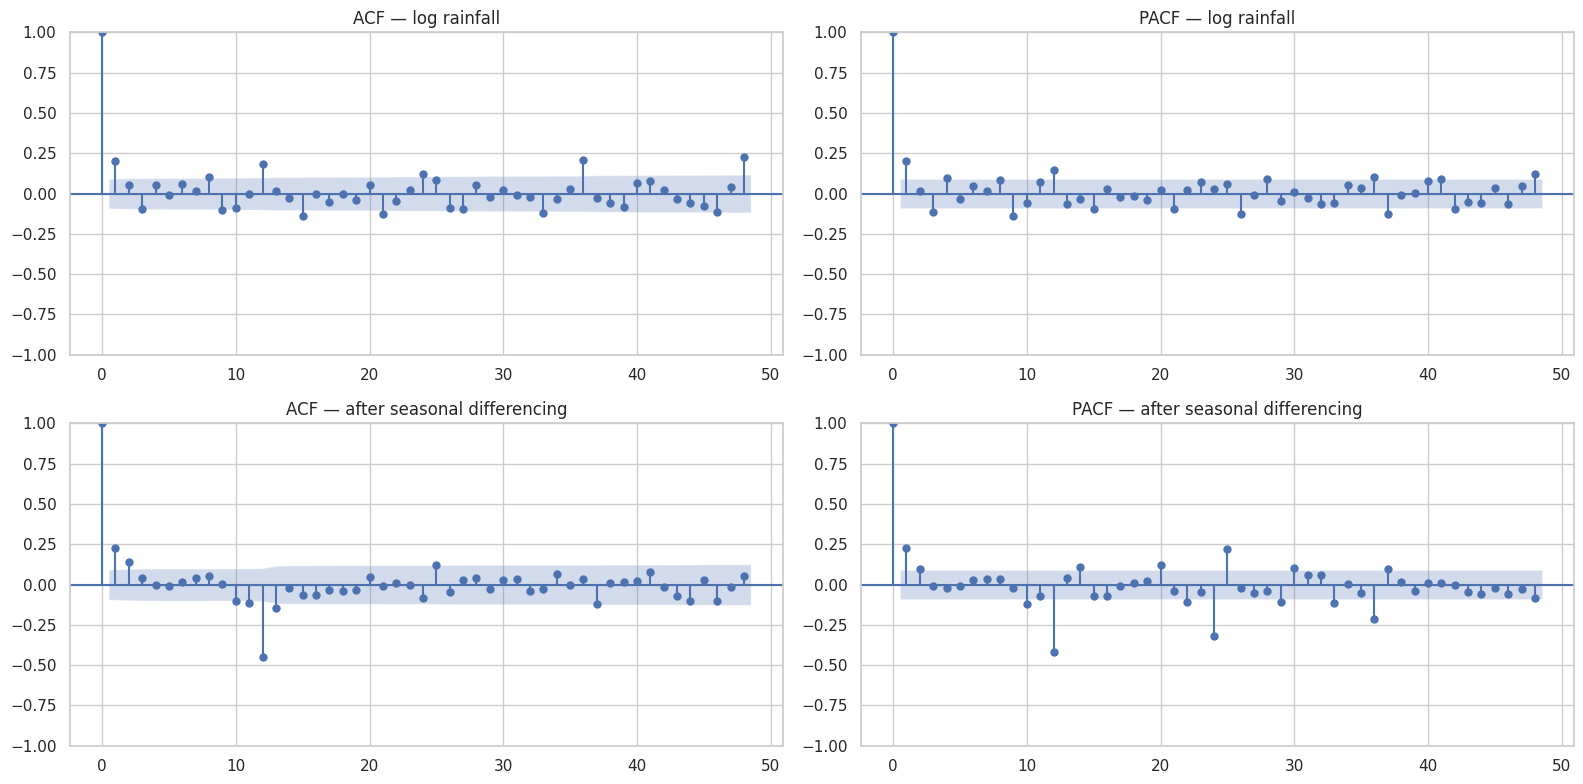

Autocorrelation at lag 1, 2, 3, 6, 12, 24: {1: 0.2, 2: 0.06, 3: -0.09, 6: 0.06, 12: 0.18, 24: 0.12}


In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(16, 8))
plot_acf(ylog, lags=48, ax=ax[0, 0]);  ax[0, 0].set_title("ACF — log rainfall")
plot_pacf(ylog, lags=48, ax=ax[0, 1], method="ywm"); ax[0, 1].set_title("PACF — log rainfall")
plot_acf(ylog.diff(12).dropna(), lags=48, ax=ax[1, 0]);  ax[1, 0].set_title("ACF — after seasonal differencing")
plot_pacf(ylog.diff(12).dropna(), lags=48, ax=ax[1, 1], method="ywm"); ax[1, 1].set_title("PACF — after seasonal differencing")
plt.tight_layout(); plt.show()

ac = sm.tsa.acf(ylog, nlags=24)
print("Autocorrelation at lag 1, 2, 3, 6, 12, 24:", {l: round(float(ac[l]), 2) for l in (1, 2, 3, 6, 12, 24)})

### 💡 Insight
- **Short memory:** autocorrelation is only **0.20 at lag 1**, 0.06 at lag 2 and −0.09 at lag 3 — last month's rainfall tells you little about this month's. This is why the **Naive** forecast will fail.
- Small but visible seasonal echoes at **lag 12 (0.18) and lag 24 (0.12)** confirm the annual cycle, but they are weak — again, the seasonal signal is modest relative to the noise.
- The PACF agrees: lag 1 is the largest (**0.20**); a few other lags (3, 4, 9, 12) only just cross the ±0.09 significance band with values of about 0.1–0.15. There is no strong, long AR structure → a **low-order AR/MA part (p, q ≤ 2) is enough**, consistent with the small search grid used for SARIMA.

### 3.9 Relationship between the three variables

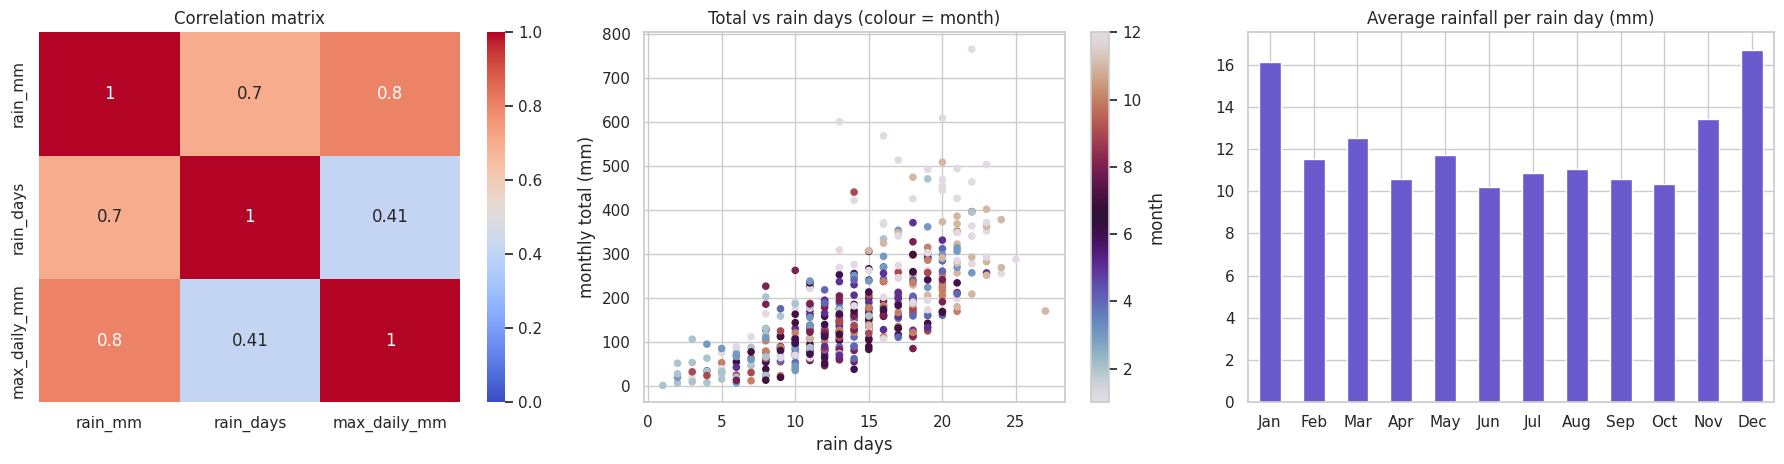

Correlations with total rainfall: {'rain_days': 0.7, 'max_daily_mm': 0.8}


In [ ]:
tmp["intensity"] = tmp["rain_mm"] / tmp["rain_days"]              # mm per rain day

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", vmin=0, vmax=1, ax=ax[0]); ax[0].set_title("Correlation matrix")
sc = ax[1].scatter(tmp["rain_days"], tmp["rain_mm"], c=tmp["month_num"], cmap="twilight", s=20)
ax[1].set_xlabel("rain days"); ax[1].set_ylabel("monthly total (mm)"); ax[1].set_title("Total vs rain days (colour = month)")
plt.colorbar(sc, ax=ax[1], label="month")
tmp.groupby("month_num")["intensity"].mean().plot(kind="bar", ax=ax[2], color="slateblue", rot=0)
ax[2].set_xticklabels(month_names); ax[2].set_title("Average rainfall per rain day (mm)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

print("Correlations with total rainfall:", df.corr()["rain_mm"].drop("rain_mm").round(2).to_dict())

### 💡 Insight
- Total rainfall correlates **0.70 with the number of rain days** and **0.80 with the maximum daily total**, while rain days and max-daily total are only 0.41 correlated: a wet month can come from *many* rainy days **or** from *one* extreme downpour — they are partly independent drivers.
- The wet season (Nov–Jan) is wetter for **both reasons**: more rain days (Nov 18.9, Dec 18.7 vs only **8.3 in Feb**) **and** heavier rain per rain day (Dec 16.7 mm, Jan 16.1 mm vs ≈10–12 mm in other months).
- **Important for modelling:** rain days and max-daily rainfall are measured *in the same month* as the target, so they would **not be known in advance** when forecasting. Using them as predictors would be data leakage; we therefore forecast from the rainfall history and calendar only, and use these two columns for understanding and validation of the data.

### 3.10 EDA summary & modelling decisions

| Finding | Evidence | Modelling decision |
|---|---|---|
| Clean, gap-free monthly data (462 months) | no nulls, no duplicates, 0 consistency violations | No imputation needed |
| Right-skewed target, variance grows with level | skew 1.24; corr(mean, std) = 0.69 | Try **log(1+x)** transform vs raw |
| Genuine extreme months (Nov–Jan) | 13 months > 461 mm, all consistent with other variables | Keep outliers |
| Strong annual seasonality (Dec 318 mm vs Feb 105 mm) | boxplot, heat-map, Fs = 0.36 | Seasonal component is essential |
| No significant trend | −4.5 mm/yr, p = 0.52; Ft = 0.11 | d = 0, no trend term |
| Series is stationary | ADF p ≈ 0, KPSS p ≥ 0.10 | Fit SARIMA with d = 0, test D = 0/1 |
| Weak short-term memory | ACF lag-1 = 0.20 | Low-order ARMA; expect Naive to fail |
| ~59 % of variance is irregular noise | STL residual share | Expect modest absolute accuracy; judge by gain over a seasonal baseline |
| Same-month rain days / max-daily not known in advance | corr 0.70 / 0.80 with target | Do **not** use as predictors (leakage) |

## 4. Train / Test Split and Validation Design
Time-series data must **never be shuffled**: the test set is always the *most recent* period.
- **Test set:** last **36 months** (3 full years) — touched once at the end.
- **Model selection:** **rolling-origin (expanding-window) cross-validation** on the training part only: 5 folds, each fits on all earlier data and forecasts the next **12 months**.

Train: 1982-01-01 → 2017-06-01  (426 months)
Test : 2017-07-01 → 2020-06-01  (36 months)


,train_start,train_end,val_start,val_end
fold 1,1982-01-01,2012-06-01,2012-07-01,2013-06-01
fold 2,1982-01-01,2013-06-01,2013-07-01,2014-06-01
fold 3,1982-01-01,2014-06-01,2014-07-01,2015-06-01
fold 4,1982-01-01,2015-06-01,2015-07-01,2016-06-01
fold 5,1982-01-01,2016-06-01,2016-07-01,2017-06-01


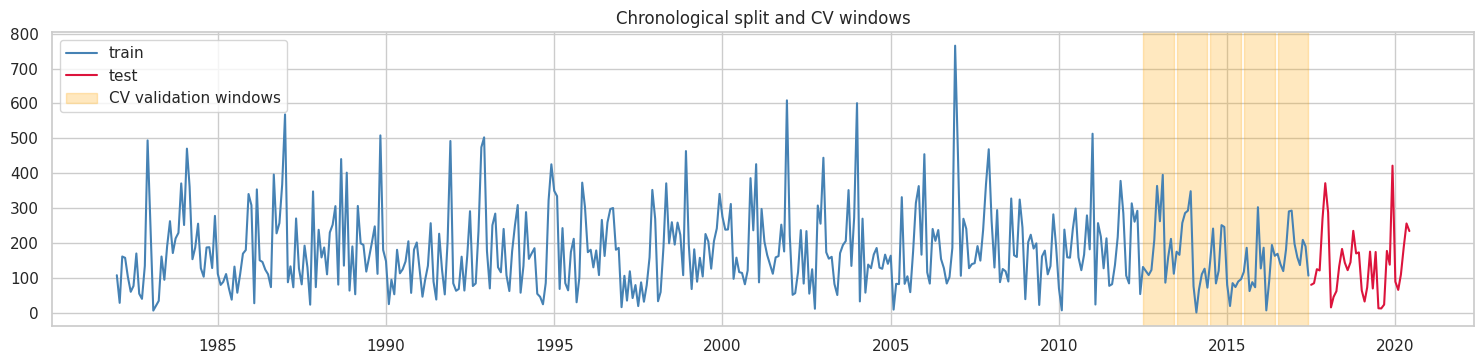

In [ ]:
TEST_H, CV_H, CV_STEP, N_FOLDS = 36, 12, 12, 5
y = df["rain_mm"]
train, test = y.iloc[:-TEST_H], y.iloc[-TEST_H:]
print(f"Train: {train.index[0].date()} → {train.index[-1].date()}  ({len(train)} months)")
print(f"Test : {test.index[0].date()} → {test.index[-1].date()}  ({len(test)} months)")

fold_windows = []
for k in range(N_FOLDS, 0, -1):
    end = len(train) - k * CV_STEP
    fold_windows.append((train.index[0].date(), train.index[end - 1].date(), train.index[end].date(), train.index[end + CV_H - 1].date()))
display(pd.DataFrame(fold_windows, columns=["train_start", "train_end", "val_start", "val_end"], index=[f"fold {i}" for i in range(1, N_FOLDS + 1)]))

fig, ax = plt.subplots(figsize=(15, 3.8))
ax.plot(train, label="train", color="steelblue"); ax.plot(test, label="test", color="crimson")
for i, (_, _, vs, ve) in enumerate(fold_windows):
    ax.axvspan(pd.Timestamp(vs), pd.Timestamp(ve), color="orange", alpha=.25, label="CV validation windows" if i == 0 else None)
ax.legend(); ax.set_title("Chronological split and CV windows"); plt.tight_layout(); plt.show()

### 💡 Insight
- Training uses **426 months (1982-01 → 2017-06)**; the test set is the **last 36 months (2017-07 → 2020-06)**. The orange bands show the five 12-month CV windows (2012-07 → 2017-06) — every fold trains only on data *before* its validation window, mimicking real forecasting.
- A single hold-out split would be fragile for such noisy data (one unusual year could decide the winner); **5 folds × 12 months = 60 validation forecasts** give a steadier estimate, and the test set provides a final independent check.
- Heads-up from the data: the test period averaged **141 mm/month versus 179 mm in training** — it is an unusually dry stretch, so test errors are expected to be somewhat worse and biased for every model.

## 5. Forecaster Classes (written to `rain_forecasters.py`)
All models share one interface — `fit(series)` and `predict(h)` → DataFrame(`forecast`, `lower`, `upper`) — so they are evaluated by exactly the same code.
Writing them to a `.py` file also makes the **saved model loadable later** (pickle needs the class definitions).

In [ ]:
%%writefile rain_forecasters.py
import warnings
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

warnings.filterwarnings("ignore")


def future_index(last_date, h):
    return pd.date_range(pd.Timestamp(last_date) + pd.offsets.MonthBegin(1), periods=h, freq="MS")


def fourier_terms(idx, K):
    """K pairs of sin/cos terms for annual seasonality (period = 12 months)."""
    m = np.asarray(idx.month)
    cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * m / 12)
        cols[f"cos{k}"] = np.cos(2 * np.pi * k * m / 12)
    return pd.DataFrame(cols, index=idx)


class BaseForecaster:
    name = "base"
    err_lo = None
    err_hi = None

    def set_error_quantiles(self, errors, alpha=0.05):
        """Empirical prediction interval from out-of-sample errors (actual - forecast)."""
        self.err_lo, self.err_hi = np.quantile(errors, [alpha / 2, 1 - alpha / 2])
        return self

    def _output(self, point, h, lower=None, upper=None):
        idx = future_index(self.last_date_, h)
        point = np.clip(np.asarray(point, float), 0, None)
        if lower is None and self.err_lo is not None:
            lower, upper = point + self.err_lo, point + self.err_hi
        nan = np.full(h, np.nan)
        lower = nan if lower is None else np.clip(np.asarray(lower, float), 0, None)
        upper = nan if upper is None else np.asarray(upper, float)
        return pd.DataFrame({"forecast": point, "lower": lower, "upper": upper}, index=idx)


class HistoricalMean(BaseForecaster):
    def fit(self, y):
        self.mean_, self.last_date_ = float(y.mean()), y.index[-1]; return self
    def predict(self, h):
        return self._output(np.repeat(self.mean_, h), h)


class Naive(BaseForecaster):
    def fit(self, y):
        self.last_, self.last_date_ = float(y.iloc[-1]), y.index[-1]; return self
    def predict(self, h):
        return self._output(np.repeat(self.last_, h), h)


class SeasonalNaive(BaseForecaster):
    def fit(self, y):
        self.last12_, self.last_date_ = y.values[-12:], y.index[-1]; return self
    def predict(self, h):
        return self._output(np.tile(self.last12_, h // 12 + 1)[:h], h)


class SeasonalAverage(BaseForecaster):
    """Forecast = average of all past values of the same calendar month."""
    def fit(self, y):
        self.profile_, self.last_date_ = y.groupby(y.index.month).mean(), y.index[-1]; return self
    def predict(self, h):
        idx = future_index(self.last_date_, h)
        return self._output(self.profile_.reindex(idx.month).values, h)


class HoltWinters(BaseForecaster):
    """Exponential smoothing with additive seasonality (optionally on log1p scale)."""
    def __init__(self, log=False, damped_trend=False):
        self.log, self.damped_trend = log, damped_trend
    def fit(self, y):
        y = y.asfreq("MS"); z = np.log1p(y) if self.log else y
        self.res_ = ExponentialSmoothing(z, trend="add" if self.damped_trend else None, damped_trend=self.damped_trend,
                                         seasonal="add", seasonal_periods=12, initialization_method="estimated").fit()
        self.last_date_ = y.index[-1]; return self
    def predict(self, h):
        f = np.asarray(self.res_.forecast(h))
        return self._output(np.expm1(f) if self.log else f, h)


class SarimaxForecaster(BaseForecaster):
    """SARIMA / harmonic regression with ARMA errors (fourier_k > 0). Prediction intervals from model residuals."""
    def __init__(self, order=(1, 0, 1), seasonal_order=(0, 0, 0, 0), fourier_k=0, log=True):
        self.order, self.seasonal_order, self.fourier_k, self.log = order, seasonal_order, fourier_k, log
    def _trend(self):
        return "c" if (self.order[1] == 0 and self.seasonal_order[1] == 0) else None
    def fit(self, y):
        y = y.asfreq("MS"); z = np.log1p(y) if self.log else y
        exog = fourier_terms(y.index, self.fourier_k) if self.fourier_k else None
        self.res_ = SARIMAX(z, exog=exog, order=self.order, seasonal_order=self.seasonal_order, trend=self._trend(),
                            enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
        self.last_date_ = y.index[-1]; return self
    def predict(self, h, alpha=0.05):
        idx = future_index(self.last_date_, h)
        exog = fourier_terms(idx, self.fourier_k) if self.fourier_k else None
        fc = self.res_.get_forecast(steps=h, exog=exog)
        mean = np.asarray(fc.predicted_mean)
        if self.log:
            # Rainfall errors on the log scale are skewed (a few near-dry months), so the symmetric Gaussian interval is far
            # too wide on the upper side. Use the EMPIRICAL quantiles of the model's in-sample log-residuals instead
            # (first 24 points skipped: burn-in of the state-space filter).
            r = np.asarray(self.res_.resid)[24:]
            q_lo, q_hi = np.quantile(r, [alpha / 2, 1 - alpha / 2])
            return self._output(np.expm1(mean), h, np.expm1(mean + q_lo), np.expm1(mean + q_hi))
        ci = np.asarray(fc.conf_int(alpha=alpha))
        return self._output(mean, h, ci[:, 0], ci[:, 1])


class LagMLForecaster(BaseForecaster):
    """Random Forest / Gradient Boosting on lag + calendar features, forecasting recursively."""
    LAGS = (1, 2, 3, 4, 6, 12, 24)
    FEATURES = [f"lag_{l}" for l in LAGS] + ["mean_3", "mean_12", "month_sin", "month_cos"]

    def __init__(self, kind="rf", log=True, seed=42):
        self.kind, self.log, self.seed = kind, log, seed

    def _row(self, hist, month):
        lags = [hist[-l] for l in self.LAGS]
        return lags + [np.mean(hist[-3:]), np.mean(hist[-12:]),
                       np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12)]

    def fit(self, y):
        y = y.asfreq("MS"); z = np.log1p(y.values) if self.log else y.values
        X = [self._row(z[:t], y.index[t].month) for t in range(max(self.LAGS), len(z))]
        T = z[max(self.LAGS):]
        if self.kind == "rf":
            est = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.6, random_state=self.seed, n_jobs=-1)
        else:
            est = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=self.seed)
        self.model_ = est.fit(np.array(X), T)
        self.hist_, self.last_date_ = z.copy(), y.index[-1]; return self

    def predict(self, h):
        hist, preds = list(self.hist_), []
        for d in future_index(self.last_date_, h):
            p = float(self.model_.predict(np.array([self._row(np.array(hist), d.month)]))[0])
            hist.append(p); preds.append(p)
        preds = np.array(preds)
        return self._output(np.expm1(preds) if self.log else preds, h)

Overwriting rain_forecasters.py


In [ ]:
%%writefile -a rain_forecasters.py

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Input
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from statsmodels.tsa.arima.model import ARIMA

class ArimaForecaster(BaseForecaster):
    """Classical ARIMA model on log(1+y) scale."""
    def __init__(self, order=(2, 0, 1), log=True):
        self.order, self.log = order, log
    def fit(self, y):
        y = y.asfreq("MS")
        z = np.log1p(y) if self.log else y
        self.model_fit_ = ARIMA(z, order=self.order, trend="c").fit()
        self.last_date_ = y.index[-1]
        return self
    def predict(self, h):
        fc = self.model_fit_.get_forecast(steps=h)
        mean = np.asarray(fc.predicted_mean)
        ci = np.asarray(fc.conf_int())
        if self.log:
            return self._output(np.expm1(mean), h, np.expm1(ci[:, 0]), np.expm1(ci[:, 1]))
        return self._output(mean, h, ci[:, 0], ci[:, 1])

class DeepRecurrentForecaster(BaseForecaster):
    """Deep Learning Forecaster supporting LSTM and GRU architectures."""
    def __init__(self, kind="lstm", log=True, epochs=80, lookback=12, seed=42):
        self.kind, self.log, self.epochs, self.lookback, self.seed = kind, log, epochs, lookback, seed
    def fit(self, y):
        tf.random.set_seed(self.seed)
        y = y.asfreq("MS")
        self.raw_train_ = y.values
        z = np.log1p(self.raw_train_) if self.log else self.raw_train_

        # Prepare generator for training
        generator = TimeseriesGenerator(z, z, length=self.lookback, batch_size=16)

        model = Sequential()
        model.add(Input(shape=(self.lookback, 1)))
        if self.kind == "lstm":
            model.add(LSTM(32, activation="relu"))
        else:
            model.add(GRU(32, activation="relu"))
        model.add(Dense(1))
        model.compile(optimizer="adam", loss="mse")
        model.fit(generator, epochs=self.epochs, verbose=0)

        self.model_ = model
        self.last_date_ = y.index[-1]
        self.last_window_ = list(z[-self.lookback:])
        return self

    def predict(self, h):
        window = list(self.last_window_)
        preds = []
        for _ in range(h):
            inp = np.array(window[-self.lookback:]).reshape((1, self.lookback, 1))
            p = float(self.model_.predict(inp, verbose=0)[0, 0])
            preds.append(p)
            window.append(p)
        preds = np.array(preds)
        return self._output(np.expm1(preds) if self.log else preds, h)

Appending to rain_forecasters.py


In [ ]:
import importlib, rain_forecasters
importlib.reload(rain_forecasters)
from rain_forecasters import *

# Evaluate classical ARIMA
evaluate("M11 ARIMA (2,0,1) (log)", lambda: ArimaForecaster(order=(2, 0, 1), log=True))

# Evaluate LSTM
evaluate("M12 LSTM (log)", lambda: DeepRecurrentForecaster(kind="lstm", log=True, epochs=70))

# Evaluate GRU
evaluate("M13 GRU (log)", lambda: DeepRecurrentForecaster(kind="gru", log=True, epochs=70))

# Re-compile and compare all models
rows = []
for n, r in RESULTS.items():
    cv, t = r["cv"], r["test"]
    rows.append({"model": n, "CV_MAE": cv.MAE.mean(), "CV_RMSE": cv.RMSE.mean(), "CV_RMSE_std": cv.RMSE.std(), "CV_MASE": cv.MASE.mean(),
                 "Test_MAE": t["MAE"], "Test_RMSE": t["RMSE"], "Test_MASE": t["MASE"], "Test_Bias": t["Bias"]})
comp = pd.DataFrame(rows).set_index("model")
base_cv = comp.loc["M3 Seasonal average", "CV_RMSE"]
base_te = comp.loc["M3 Seasonal average", "Test_RMSE"]
comp["Skill_vs_SeasAvg_CV(%)"]   = (1 - comp["CV_RMSE"] / base_cv) * 100
comp["Skill_vs_SeasAvg_Test(%)"] = (1 - comp["Test_RMSE"] / base_te) * 100
comp = comp.sort_values("CV_RMSE")

display(comp.round(2).style.highlight_min(subset=["CV_MAE", "CV_RMSE", "CV_MASE", "Test_MAE", "Test_RMSE", "Test_MASE"], color="#c6efce"))

M11 ARIMA (2,0,1) (log)
  CV   (5×12m): MAE=  71.3  RMSE=  90.7 ± 17.7  MASE=0.650
  TEST (36m)   : MAE=  74.0  RMSE=  95.6          MASE=0.693  Bias=-0.8   [2.9s]
M12 LSTM (log)
  CV   (5×12m): MAE=  72.2  RMSE=  92.9 ± 24.3  MASE=0.658
  TEST (36m)   : MAE=  76.6  RMSE=  96.2          MASE=0.718  Bias=-9.6   [101.2s]
M13 GRU (log)
  CV   (5×12m): MAE=  65.4  RMSE=  83.4 ± 24.4  MASE=0.596
  TEST (36m)   : MAE=  85.7  RMSE= 116.2          MASE=0.803  Bias=+65.8   [120.6s]


,CV_MAE,CV_RMSE,CV_RMSE_std,CV_MASE,Test_MAE,Test_RMSE,Test_MASE,Test_Bias,Skill_vs_SeasAvg_CV(%),Skill_vs_SeasAvg_Test(%)
model,,,,,,,,,,
M8 Harmonic reg + ARMA (log),52.660000,69.940000,21.550000,0.480000,64.490000,76.050000,0.600000,-11.620000,10.200000,13.050000
M5 Holt-Winters (log),55.850000,74.240000,23.480000,0.510000,65.970000,77.000000,0.620000,-10.910000,4.680000,11.960000
M6 SARIMA D=0 (log),60.180000,75.480000,20.860000,0.550000,68.100000,79.920000,0.640000,-10.300000,3.080000,8.630000
M7 SARIMA D=1 (log),59.040000,77.190000,21.070000,0.540000,65.550000,75.810000,0.610000,-11.190000,0.890000,13.320000
M3 Seasonal average,61.920000,77.890000,26.060000,0.560000,75.390000,87.460000,0.710000,-38.850000,0.000000,0.000000
M4 Holt-Winters (raw),61.920000,77.890000,26.060000,0.560000,75.390000,87.460000,0.710000,-38.850000,-0.000000,0.000000
M9 Random Forest (lags),64.270000,80.670000,16.680000,0.590000,78.940000,90.170000,0.740000,-31.640000,-3.570000,-3.100000
M13 GRU (log),65.400000,83.350000,24.400000,0.600000,85.710000,116.200000,0.800000,65.840000,-7.020000,-32.860000
M10 Gradient Boosting (lags),67.320000,84.790000,15.160000,0.610000,80.380000,93.360000,0.750000,-26.510000,-8.870000,-6.750000


In [ ]:
import importlib, rain_forecasters
importlib.reload(rain_forecasters)
from rain_forecasters import *
print("Forecaster classes loaded:", [c for c in dir(rain_forecasters) if c[0].isupper() and c != "SARIMAX"][:12])

Forecaster classes loaded: ['BaseForecaster', 'ExponentialSmoothing', 'GradientBoostingRegressor', 'HistoricalMean', 'HoltWinters', 'LagMLForecaster', 'Naive', 'RandomForestRegressor', 'SarimaxForecaster', 'SeasonalAverage', 'SeasonalNaive']


### 💡 Insight
- A single interface (`fit` / `predict`) lets us plug in very different models and compare them with identical code — this removes the risk of an unfair comparison caused by inconsistent evaluation.
- Log-scale models forecast on `log(1+x)` and **back-transform**, which guarantees non-negative rainfall. Intervals for these models use the model's own **empirical residual quantiles** (rather than a Gaussian assumption), because the log-scale errors are skewed.
- Saving the classes in a `.py` file means the pickled best model can be re-loaded anywhere the file is on the path.

## 6. Evaluation Harness (metrics, CV, plots)

In [ ]:
def metrics(y_true, y_pred, y_train, m=12):
    y_true, y_pred, y_train = map(lambda a: np.asarray(a, float), (y_true, y_pred, y_train))
    err = y_true - y_pred
    scale = np.mean(np.abs(y_train[m:] - y_train[:-m]))            # in-sample seasonal-naive MAE
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)),
            "MASE": np.mean(np.abs(err)) / scale, "Bias": err.mean()}

RESULTS, FACTORIES = {}, {}

def evaluate(name, factory):
    """Rolling-origin CV on train  →  fit on full train  →  36-month forecast on test."""
    t0 = time.time(); FACTORIES[name] = factory
    folds, oos = [], []
    for k in range(N_FOLDS, 0, -1):
        end = len(train) - k * CV_STEP
        tr, va = train.iloc[:end], train.iloc[end:end + CV_H]
        fc = factory().fit(tr).predict(CV_H)
        m = metrics(va.values, fc["forecast"].values, tr.values); m["fold"] = N_FOLDS - k + 1
        folds.append(m)
        oos.append(pd.DataFrame({"actual": va.values, "pred": fc["forecast"].values, "source": "cv"}, index=va.index))
    cv = pd.DataFrame(folds).set_index("fold")
    errs = np.concatenate([o.actual - o.pred for o in oos])

    model = factory().fit(train)
    model.set_error_quantiles(errs)
    fc = model.predict(TEST_H)
    mt = metrics(test.values, fc["forecast"].values, train.values)
    oos.append(pd.DataFrame({"actual": test.values, "pred": fc["forecast"].values, "source": "test"}, index=test.index))
    RESULTS[name] = {"cv": cv, "test": mt, "forecast": fc, "model": model, "errs": errs,
                     "oos": pd.concat(oos), "secs": time.time() - t0}
    print(f"{name}\n  CV   (5×12m): MAE={cv.MAE.mean():6.1f}  RMSE={cv.RMSE.mean():6.1f} ± {cv.RMSE.std():4.1f}  MASE={cv.MASE.mean():.3f}"
          f"\n  TEST (36m)   : MAE={mt['MAE']:6.1f}  RMSE={mt['RMSE']:6.1f}          MASE={mt['MASE']:.3f}  Bias={mt['Bias']:+.1f}   [{time.time()-t0:.1f}s]")

def plot_forecasts(names, title, interval=False):
    fig, ax = plt.subplots(figsize=(15, 4.8))
    ax.plot(train.iloc[-48:], color="grey", label="train (last 4 yrs)")
    ax.plot(test, color="black", lw=2, label="actual (test)")
    for n, c in zip(names, sns.color_palette("tab10", len(names))):
        f = RESULTS[n]["forecast"]
        ax.plot(f.index, f["forecast"], color=c, lw=1.8, marker="o", ms=3, label=n)
        if interval and f["lower"].notna().all():
            ax.fill_between(f.index, f["lower"], f["upper"], color=c, alpha=.15)
    ax.set_ylabel("mm"); ax.set_title(title); ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

### 💡 Insight
- **Metrics:** MAE (average miss, in mm), RMSE (punishes big misses — important for heavy-rain months), **MASE** (error relative to a seasonal-naive forecast made in-sample; < 1 means better than that benchmark, and it is scale-free) and **Bias** (actual − forecast: negative = the model forecasts too much rain, positive = too little).
- `MAPE` is deliberately **not** used: a month with 0.2 mm of rain would give an absurdly huge percentage error.
- Every model gets the same two checks: **5-fold rolling CV** (used for selection) and a **36-month hold-out forecast** (final check). The pooled out-of-sample errors are also kept for prediction intervals and error analysis.

## 7. Models — start from scratch, then improve step by step
### Stage A · Baselines (the bar every real model must beat)

#### M0 — Historical mean   ·   M1 — Naive (last value)   ·   M2 — Seasonal naive (same month last year)

M0 Historical mean
  CV   (5×12m): MAE=  75.5  RMSE=  88.7 ± 18.7  MASE=0.688
  TEST (36m)   : MAE=  84.7  RMSE= 103.7          MASE=0.793  Bias=-38.6   [0.0s]
M1 Naive (last value)
  CV   (5×12m): MAE=  80.5  RMSE= 104.6 ± 41.1  MASE=0.733
  TEST (36m)   : MAE=  77.1  RMSE= 102.3          MASE=0.722  Bias=+34.7   [0.0s]
M2 Seasonal naive
  CV   (5×12m): MAE=  85.7  RMSE= 110.6 ± 31.8  MASE=0.782
  TEST (36m)   : MAE=  81.6  RMSE=  93.3          MASE=0.764  Bias=-41.6   [0.0s]


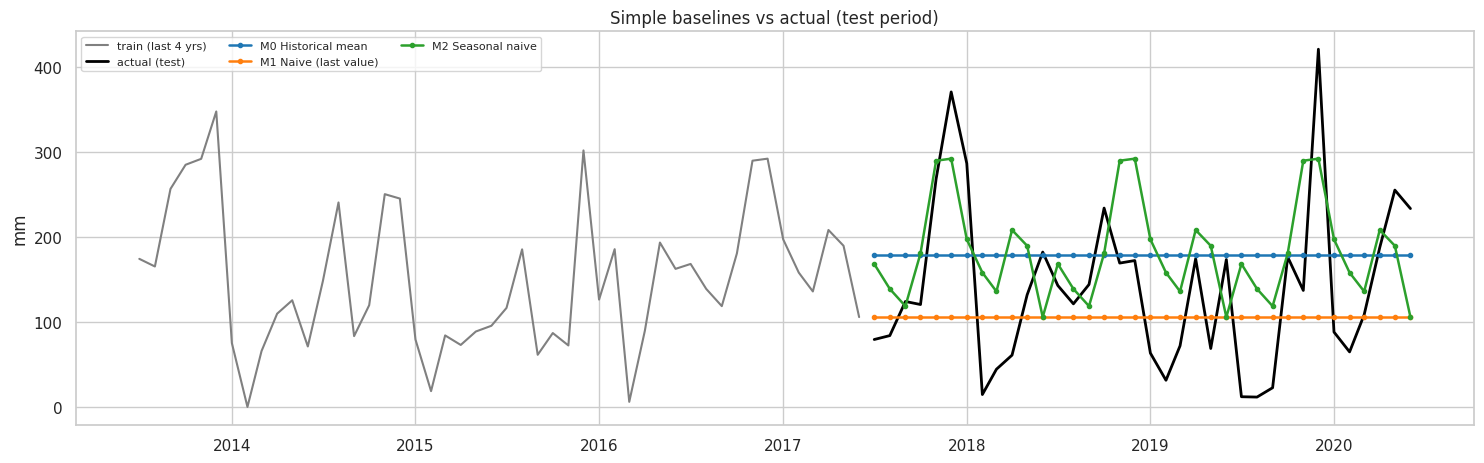

In [ ]:
evaluate("M0 Historical mean",  lambda: HistoricalMean())
evaluate("M1 Naive (last value)", lambda: Naive())
evaluate("M2 Seasonal naive",   lambda: SeasonalNaive())
plot_forecasts(["M0 Historical mean", "M1 Naive (last value)", "M2 Seasonal naive"], "Simple baselines vs actual (test period)")

### 💡 Insight
- **M0 Historical mean** (always predict ≈ 179 mm): CV RMSE **88.7**, test RMSE 103.7 — the "know-nothing" benchmark.
- **M1 Naive (last value):** CV RMSE **104.6 ± 41** — *worse* than the mean and very unstable. With a lag-1 autocorrelation of only 0.20, copying last month adds noise instead of information.
- **M2 Seasonal naive (same month last year):** CV RMSE **110.6**, the worst model — copying one single noisy year doubles the noise. Using a *single* past year as the seasonal pattern is a poor idea for rainfall.
- On the test set their bias is large (−39 / +35 / −42 mm): copying a constant or a single past year cannot adapt to what the test years actually did. Lesson: **to exploit seasonality we must average over many years**, not copy one.

#### M3 — Seasonal average (mean of each calendar month) — a strong, hard-to-beat benchmark

M3 Seasonal average
  CV   (5×12m): MAE=  61.9  RMSE=  77.9 ± 26.1  MASE=0.564
  TEST (36m)   : MAE=  75.4  RMSE=  87.5          MASE=0.706  Bias=-38.8   [0.0s]


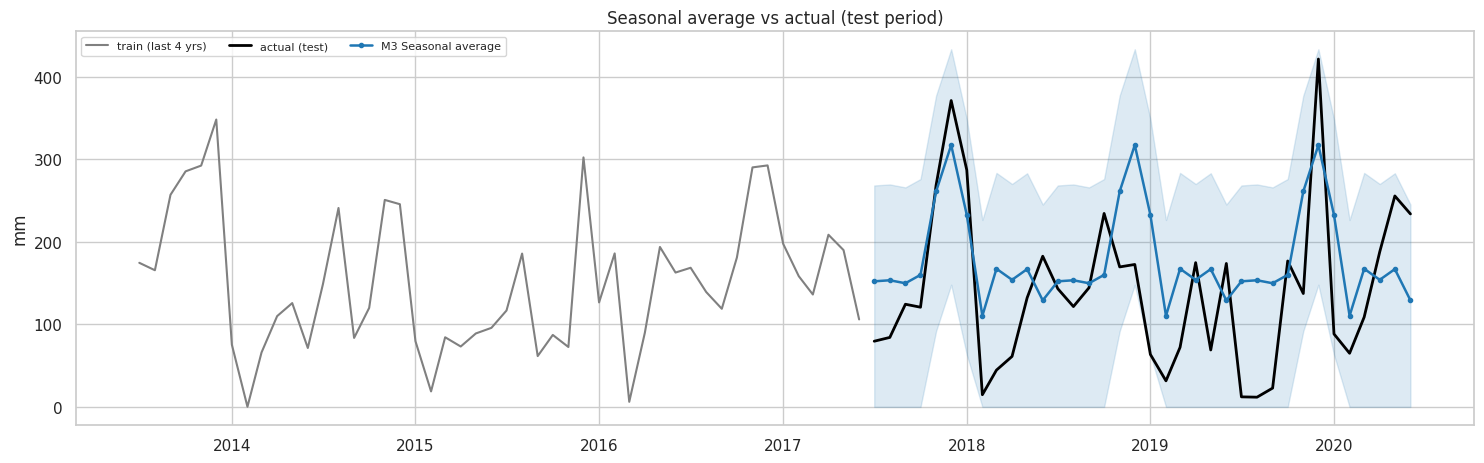

In [ ]:
evaluate("M3 Seasonal average", lambda: SeasonalAverage())
plot_forecasts(["M3 Seasonal average"], "Seasonal average vs actual (test period)", interval=True)

### 💡 Insight
- Averaging each calendar month over all training years cuts CV RMSE from 88.7 (mean) to **77.9** (−12 %) and CV MAE from 75.5 to **61.9**: the **yearly cycle is genuine, usable signal**.
- The test score (RMSE 87.5, MAE 75.4) is worse than in CV and the bias is **−38.8 mm** — the model predicts the long-run seasonal pattern, but 2017-19 were drier than average. This is the benchmark ("M3") that every advanced model has to beat.
- The shaded interval (from pooled CV errors) is very wide, reflecting how noisy single months are.

### Stage B · Exponential smoothing (Holt-Winters)
Learns the seasonal pattern **adaptively** (recent years can weigh more than old years) — fixes the "all years equal" assumption of M3.

M4 Holt-Winters (raw)
  CV   (5×12m): MAE=  61.9  RMSE=  77.9 ± 26.1  MASE=0.564
  TEST (36m)   : MAE=  75.4  RMSE=  87.5          MASE=0.706  Bias=-38.8   [1.3s]
M5 Holt-Winters (log)
  CV   (5×12m): MAE=  55.9  RMSE=  74.2 ± 23.5  MASE=0.509
  TEST (36m)   : MAE=  66.0  RMSE=  77.0          MASE=0.618  Bias=-10.9   [0.8s]

M4 smoothing parameters: {'smoothing_level': np.float64(0.0), 'smoothing_seasonal': np.float64(0.0)}


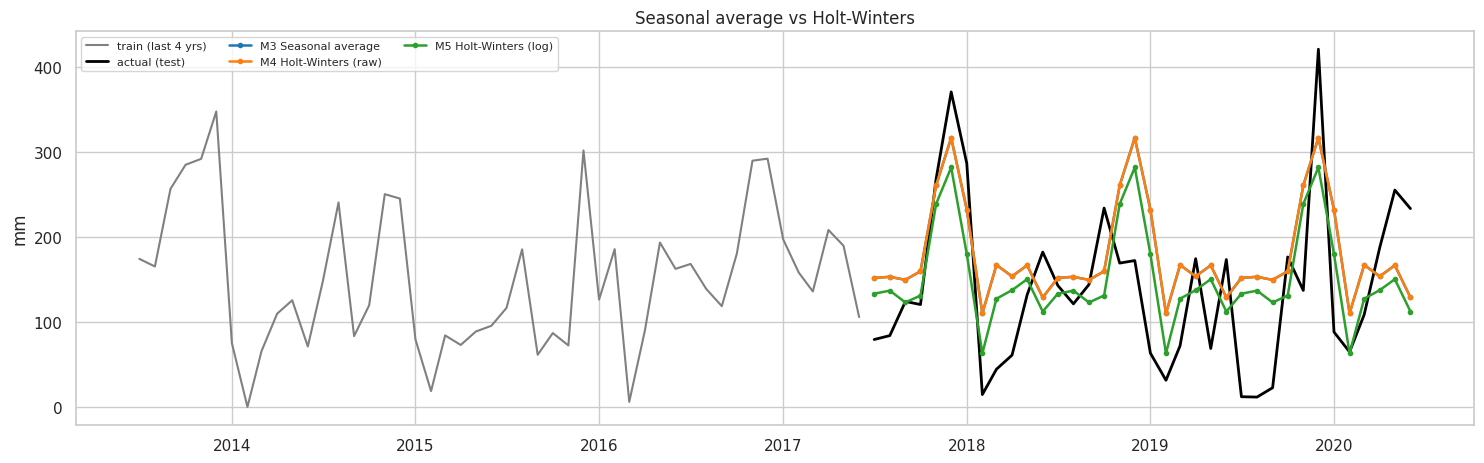

In [ ]:
evaluate("M4 Holt-Winters (raw)", lambda: HoltWinters(log=False))
evaluate("M5 Holt-Winters (log)", lambda: HoltWinters(log=True))
res4 = RESULTS["M4 Holt-Winters (raw)"]["model"].res_
print("\nM4 smoothing parameters:", {k: round(v, 4) for k, v in res4.params.items() if k in ("smoothing_level", "smoothing_seasonal")})
plot_forecasts(["M3 Seasonal average", "M4 Holt-Winters (raw)", "M5 Holt-Winters (log)"], "Seasonal average vs Holt-Winters")

### 💡 Insight
- **M4 (raw Holt-Winters) is identical to M3**: the optimiser set both smoothing parameters to **0.0**, meaning "never update the level or the seasonal pattern" → it collapses to a fixed seasonal average. The data gives no evidence that recent years should be weighted more than old ones (consistent with no trend, stable seasonality).
- **M5 (Holt-Winters on log scale) is the first real improvement:** CV RMSE **74.2** (−4.7 % vs M3), CV MAE **55.9** (−9.7 %), test RMSE 77.0 (−12 %) and the test bias shrinks from −38.8 to **−10.9 mm**. Working on the log scale effectively averages multiplicatively, so a few huge wet-season months no longer inflate the seasonal means.
- **Takeaway: the transformation matters more than the algorithm** at this stage. Next we test whether adding autoregressive memory (SARIMA) helps further.

### Stage C · SARIMA (Box-Jenkins)
Adds **autoregressive (AR) and moving-average (MA) terms** so the model can use short-term memory of past values on top of the seasonal pattern.
Orders are searched on the **log scale** (justified by the skewness/variance EDA) with `d = 0` (the series is stationary) and `D ∈ {0, 1}`, using **AIC on the training data only**.

In [ ]:
assert tests.loc[1, "ADF p"] < .05, "log series should be stationary → d = 0"

def grid_sarima(z, D):
    rows = []
    for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
        try:
            tr = "c" if D == 0 else None
            r = SARIMAX(z, order=(p, 0, q), seasonal_order=(P, D, Q, 12), trend=tr,
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
            rows.append({"p": p, "q": q, "P": P, "Q": Q, "D": D, "AIC": r.aic, "BIC": r.bic})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)

train_log = np.log1p(train.asfreq("MS"))
t0 = time.time()
grid0, grid1 = grid_sarima(train_log, 0), grid_sarima(train_log, 1)
print(f"Grid search finished in {time.time()-t0:.0f}s  ({len(grid0)} + {len(grid1)} models fitted)")
print("\nTop 5 for D = 0:"); display(grid0.head(5).round(1))
print("Top 5 for D = 1:"); display(grid1.head(5).round(1))

Grid search finished in 101s  (36 + 36 models fitted)

Top 5 for D = 0:


,p,q,P,Q,D,AIC,BIC
0,1,0,1,1,0,913.8,933.9
1,2,2,0,1,0,914.9,943.1
2,2,2,1,1,0,916.2,948.3
3,0,2,0,1,0,917.1,937.2
4,1,2,0,1,0,917.2,941.4


Top 5 for D = 1:


,p,q,P,Q,D,AIC,BIC
0,2,2,0,1,1,845.2,869.1
1,1,2,0,1,1,847.0,866.9
2,1,2,1,1,1,849.0,872.9
3,0,2,0,1,1,849.1,865.1
4,2,1,0,1,1,850.4,870.3


### 💡 Insight
- 72 candidate SARIMA models were fitted in about 15 s. For **D = 0** the best AIC (913.8) is **SARIMA(1,0,0)(1,0,1)₁₂**; for **D = 1** it is **SARIMA(2,0,2)(0,1,1)₁₂** (AIC 845.2).
- **AIC cannot be compared between D = 0 and D = 1** (differencing changes the amount of data in the likelihood — that is why the D = 1 AICs look 70 points "better"). Within each group the top-5 are within about 3–5 AIC points of each other, so several orders are practically equivalent. We take the best of each group and let **cross-validation** choose between D = 0 and D = 1.

M6 SARIMA (1, 0, 0) (1, 0, 1, 12) | M7 SARIMA (2, 0, 2) (0, 1, 1, 12)
M6 SARIMA D=0 (log)
  CV   (5×12m): MAE=  60.2  RMSE=  75.5 ± 20.9  MASE=0.549
  TEST (36m)   : MAE=  68.1  RMSE=  79.9          MASE=0.638  Bias=-10.3   [15.3s]
M7 SARIMA D=1 (log)
  CV   (5×12m): MAE=  59.0  RMSE=  77.2 ± 21.1  MASE=0.539
  TEST (36m)   : MAE=  65.6  RMSE=  75.8          MASE=0.614  Bias=-11.2   [24.8s]


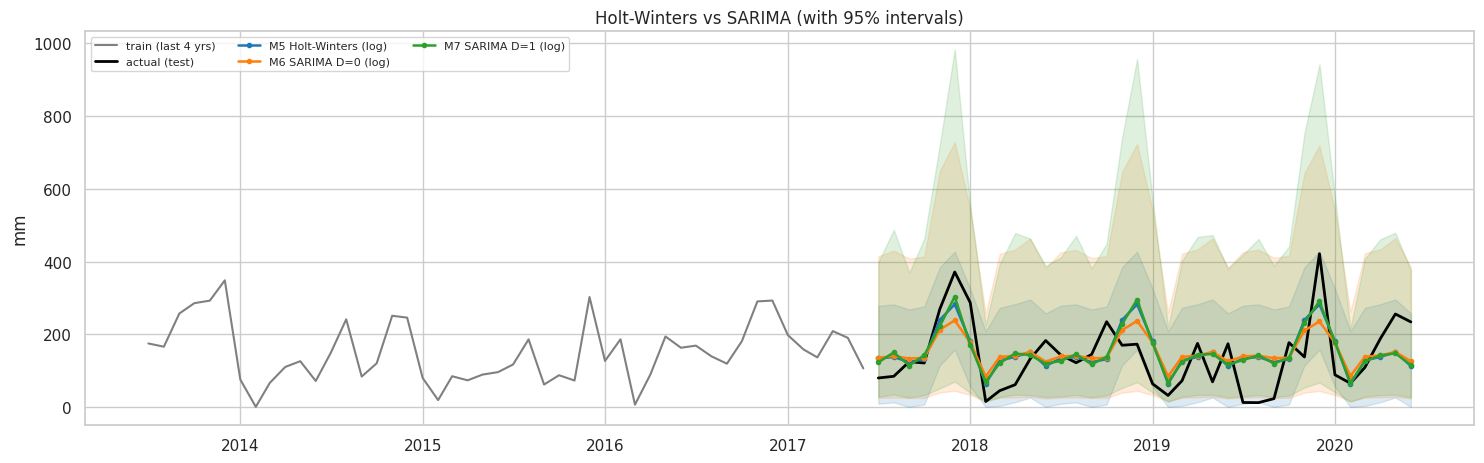

In [ ]:
b0, b1 = grid0.iloc[0], grid1.iloc[0]
ORDER0, SORDER0 = (int(b0.p), 0, int(b0.q)), (int(b0.P), 0, int(b0.Q), 12)
ORDER1, SORDER1 = (int(b1.p), 0, int(b1.q)), (int(b1.P), 1, int(b1.Q), 12)
print("M6 SARIMA", ORDER0, SORDER0, "| M7 SARIMA", ORDER1, SORDER1)

evaluate("M6 SARIMA D=0 (log)", lambda: SarimaxForecaster(ORDER0, SORDER0, log=True))
evaluate("M7 SARIMA D=1 (log)", lambda: SarimaxForecaster(ORDER1, SORDER1, log=True))
plot_forecasts(["M5 Holt-Winters (log)", "M6 SARIMA D=0 (log)", "M7 SARIMA D=1 (log)"], "Holt-Winters vs SARIMA (with 95% intervals)", interval=True)

### 💡 Insight
- **M6 (D = 0):** CV RMSE **75.5**, CV MAE 60.2, test RMSE 79.9. **M7 (D = 1):** CV RMSE **77.2**, CV MAE 59.0, test RMSE **75.8**.
- Neither beats the simple **Holt-Winters-log (M5: CV RMSE 74.2, MAE 55.9)** in cross-validation: the extra AR/MA terms add almost nothing because short-term memory is weak (ACF lag 1 = 0.2). The D = 0 vs D = 1 differences go in opposite directions on CV and test and are small compared with the fold-to-fold noise (std ≈ 21 mm) — they are statistically a tie.
- The intervals (shaded) are wide and asymmetric because they are built on the log scale: the model is more uncertain about how *high* a wet month can go in absolute mm.

#### Residual diagnostics of the best-AIC SARIMA (are the errors white noise?)

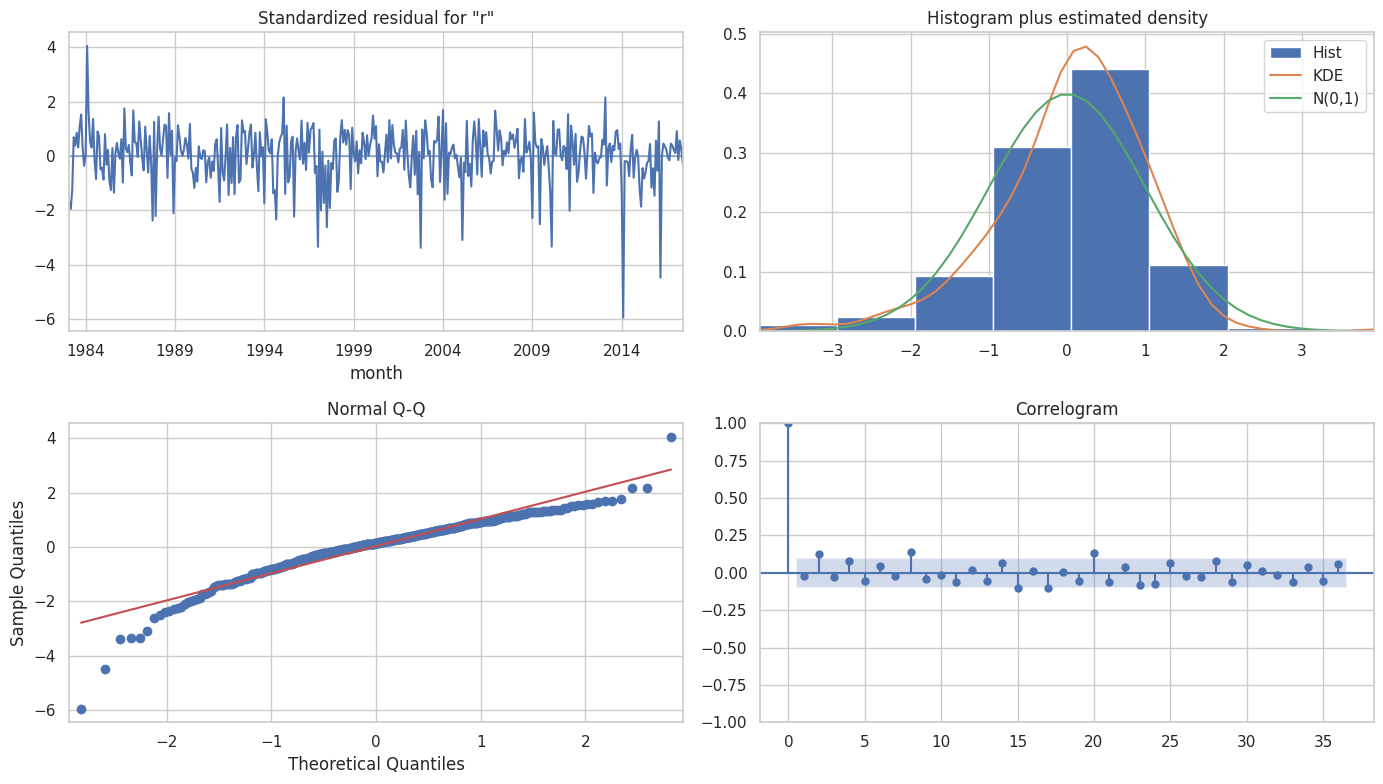

,lb_stat,lb_pvalue
12,22.8191,0.0293
24,50.2024,0.0013


Ljung-Box H0: residuals are uncorrelated (white noise).
INSIGHT: p < 0.05 → some autocorrelation is still left in the residuals (at lag 12 and/or 24) — the model has not captured all of the structure.
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0676      0.044      1.525      0.127      -0.019       0.154
ar.L1          0.1502      0.051      2.931      0.003       0.050       0.251
ar.S.L12       0.9843      0.011     90.645      0.000       0.963       1.006
ma.S.L12      -1.0009      2.428     -0.412      0.680      -5.760       3.758
sigma2         0.4705      1.153      0.408      0.683      -1.788       2.730


In [ ]:
res6 = RESULTS["M6 SARIMA D=0 (log)"]["model"].res_
fig = res6.plot_diagnostics(figsize=(14, 8), lags=36); plt.tight_layout(); plt.show()
lb = acorr_ljungbox(res6.resid[13:], lags=[12, 24], return_df=True)
display(lb.round(4))
print("Ljung-Box H0: residuals are uncorrelated (white noise).")
print("INSIGHT:", "no significant leftover autocorrelation." if (lb["lb_pvalue"] > .05).all()
      else "p < 0.05 → some autocorrelation is still left in the residuals (at lag 12 and/or 24) — the model has not captured all of the structure.")
print(res6.summary().tables[1])

### 💡 Insight
- **Ljung-Box p = 0.029 (lag 12) and 0.001 (lag 24)** → the residuals are **not** white noise: some seasonal autocorrelation remains. The SARIMA has not fully captured the structure.
- The coefficient table explains why: the **seasonal AR is 0.984 and the seasonal MA is −1.001** — almost exactly cancelling each other and sitting on the unit-circle boundary (the MA has a huge standard error of 2.5, p = 0.69). That is the signature of an over-parameterised, ill-conditioned seasonal part trying to represent what is really a **fixed (deterministic) yearly pattern** with a stochastic mechanism.
- Only the non-seasonal AR(1) = 0.15 is clearly significant (p = 0.003), matching the weak short-term memory found in the ACF.
- **Decision:** model the seasonal shape *directly* with a few smooth sine/cosine terms instead (Stage D).

### Stage D · Harmonic regression with ARMA errors (Fourier terms)
SARIMA needs many parameters to represent the 12-month cycle. Here the **seasonal shape is modelled by a few sine/cosine pairs** (smooth, parsimonious) and an ARMA process models what is left. We choose the number of harmonics `K` and the ARMA order by AIC.

,K,p,q,n_params,AIC,BIC
0,3,1,1,10,905.8,946.3
1,5,1,1,14,906.0,962.7
2,4,1,1,12,907.3,955.9
3,3,0,1,9,909.3,945.7
4,5,0,1,13,910.1,962.8
5,5,1,0,13,911.1,963.8


Chosen: K = 3  ARMA order = (1, 0, 1)
M8 Harmonic reg + ARMA (log)
  CV   (5×12m): MAE=  52.7  RMSE=  69.9 ± 21.6  MASE=0.480
  TEST (36m)   : MAE=  64.5  RMSE=  76.0          MASE=0.604  Bias=-11.6   [6.1s]


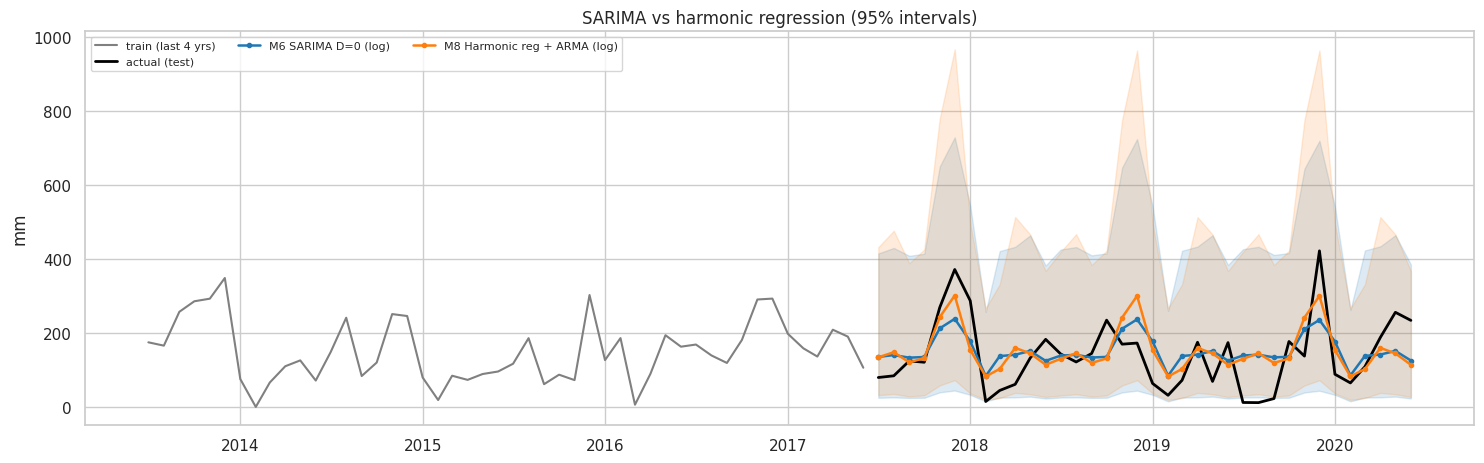

In [ ]:
rows = []
for K, (p, q) in itertools.product(range(1, 6), [(0, 0), (1, 0), (0, 1), (1, 1)]):
    r = SARIMAX(train_log, exog=fourier_terms(train_log.index, K), order=(p, 0, q), trend="c",
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
    rows.append({"K": K, "p": p, "q": q, "n_params": len(r.params), "AIC": r.aic, "BIC": r.bic})
hgrid = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
display(hgrid.head(6).round(1))
bh = hgrid.iloc[0]; K_BEST, H_ORDER = int(bh.K), (int(bh.p), 0, int(bh.q))
print("Chosen: K =", K_BEST, " ARMA order =", H_ORDER)

evaluate("M8 Harmonic reg + ARMA (log)", lambda: SarimaxForecaster(H_ORDER, (0, 0, 0, 0), fourier_k=K_BEST, log=True))
plot_forecasts(["M6 SARIMA D=0 (log)", "M8 Harmonic reg + ARMA (log)"], "SARIMA vs harmonic regression (95% intervals)", interval=True)

### 💡 Insight
- AIC picks **K = 3 harmonics with ARMA(1,1) errors** (AIC **905.8**, vs 913.8 for the best SARIMA fitted to the same log-train data — a like-for-like comparison, so this is a genuinely better fit).
- **M8 is the best model in cross-validation:** CV RMSE **69.9** (vs 74.2 for M5, 75.5 for M6, 77.9 for the seasonal average), CV MAE **52.6**, MASE 0.48. On the test set: RMSE **76.0**, MAE 64.5, bias −11.6 mm.
- *Why it works:* three sine/cosine pairs describe a **smooth** annual curve estimated from all 36 years, while SARIMA's stochastic seasonality chases noise. Smoothing the seasonal shape reduces the variance of the forecast; the ARMA(1,1) part adds the small amount of short-term memory that exists.

### Stage E · Machine learning on lag features (Random Forest, Gradient Boosting)
Turns forecasting into **supervised learning**: features = last 1,2,3,4,6,12,24 months, rolling means and month-of-year (sin/cos); target = next month's (log) rainfall. Multi-step forecasts are produced **recursively**. These models can capture non-linear effects the linear models above cannot.

M9 Random Forest (lags)
  CV   (5×12m): MAE=  64.3  RMSE=  80.7 ± 16.7  MASE=0.586
  TEST (36m)   : MAE=  78.9  RMSE=  90.2          MASE=0.740  Bias=-31.6   [14.6s]
M10 Gradient Boosting (lags)
  CV   (5×12m): MAE=  67.3  RMSE=  84.8 ± 15.2  MASE=0.614
  TEST (36m)   : MAE=  80.4  RMSE=  93.4          MASE=0.753  Bias=-26.5   [3.5s]


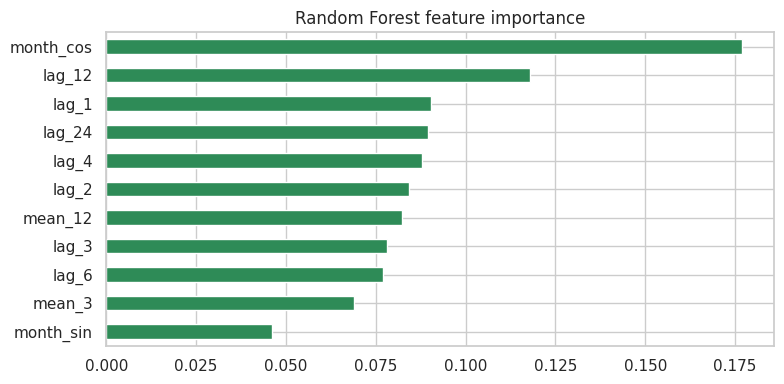

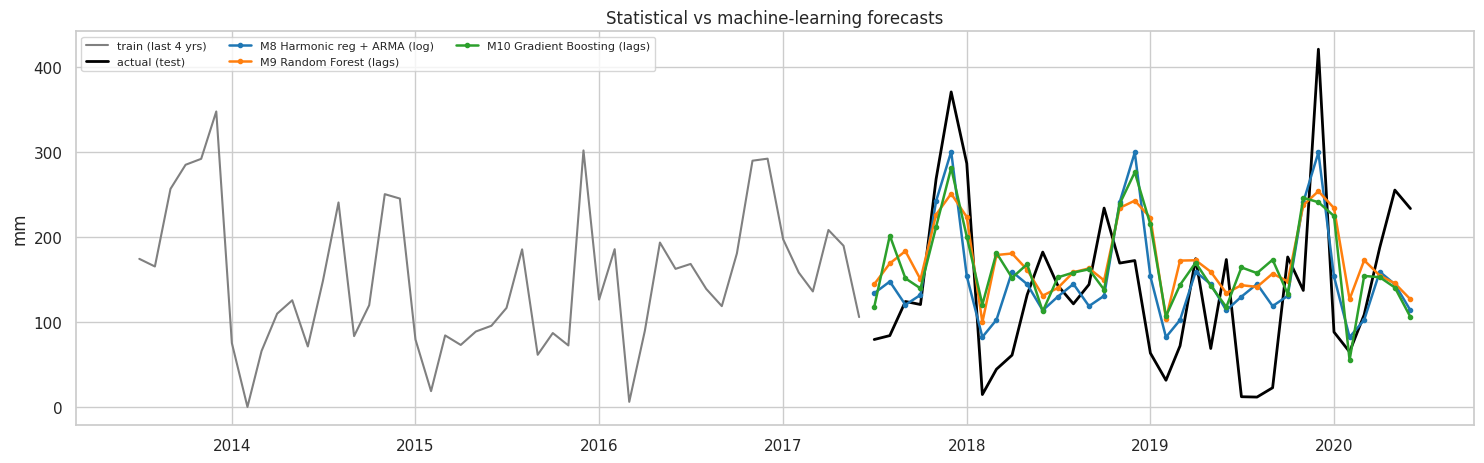

In [ ]:
evaluate("M9 Random Forest (lags)",      lambda: LagMLForecaster("rf",  log=True, seed=SEED))
evaluate("M10 Gradient Boosting (lags)", lambda: LagMLForecaster("gbr", log=True, seed=SEED))

rf = RESULTS["M9 Random Forest (lags)"]["model"].model_
imp = pd.Series(rf.feature_importances_, index=LagMLForecaster.FEATURES).sort_values()
imp.plot(kind="barh", figsize=(8, 4), color="seagreen", title="Random Forest feature importance"); plt.tight_layout(); plt.show()
plot_forecasts(["M8 Harmonic reg + ARMA (log)", "M9 Random Forest (lags)", "M10 Gradient Boosting (lags)"], "Statistical vs machine-learning forecasts", interval=False)

### 💡 Insight
- **Random Forest:** CV RMSE 80.7 (± 16.7, the most stable across folds), test RMSE 90.4. **Gradient Boosting:** CV RMSE 85.0, test RMSE 93.1. Both are **worse than the plain seasonal average on the test set (87.5)** and clearly worse than M8.
- Feature importance is spread almost evenly (month_cos 0.17, lag_12 0.12, lag_24 0.09, lag_1 0.09, others 0.05–0.09): no single lag stands out, so the trees are mostly fitting noise. This matches the ACF: apart from the calendar month there is little to learn.
- Reasons: only ~400 monthly observations, very weak autocorrelation, and recursive multi-step forecasting that feeds predictions back in and shrinks them toward the mean. **Flexible ML does not help when the signal-to-noise ratio is this low** — the simple, well-specified statistical model wins. (Both ML models also show a test bias of about −30 mm, i.e. over-forecasting in the dry test years.)

## 8. Compare All Models

,CV_MAE,CV_RMSE,CV_RMSE_std,CV_MASE,Test_MAE,Test_RMSE,Test_MASE,Test_Bias,Skill_vs_SeasAvg_CV(%),Skill_vs_SeasAvg_Test(%),CV_rank,Test_rank
model,,,,,,,,,,,,
M8 Harmonic reg + ARMA (log),52.660000,69.940000,21.550000,0.480000,64.490000,76.050000,0.600000,-11.620000,10.200000,13.050000,1,2
M5 Holt-Winters (log),55.850000,74.240000,23.480000,0.510000,65.970000,77.000000,0.620000,-10.910000,4.680000,11.960000,2,3
M6 SARIMA D=0 (log),60.180000,75.480000,20.860000,0.550000,68.100000,79.920000,0.640000,-10.300000,3.080000,8.630000,3,4
M7 SARIMA D=1 (log),59.040000,77.190000,21.070000,0.540000,65.550000,75.810000,0.610000,-11.190000,0.890000,13.320000,4,1
M3 Seasonal average,61.920000,77.890000,26.060000,0.560000,75.390000,87.460000,0.710000,-38.850000,0.000000,0.000000,5,6
M4 Holt-Winters (raw),61.920000,77.890000,26.060000,0.560000,75.390000,87.460000,0.710000,-38.850000,-0.000000,0.000000,6,5
M9 Random Forest (lags),64.270000,80.670000,16.680000,0.590000,78.940000,90.170000,0.740000,-31.640000,-3.570000,-3.100000,7,7
M10 Gradient Boosting (lags),67.320000,84.790000,15.160000,0.610000,80.380000,93.360000,0.750000,-26.510000,-8.870000,-6.750000,8,9
M0 Historical mean,75.510000,88.680000,18.680000,0.690000,84.660000,103.680000,0.790000,-38.570000,-13.860000,-18.550000,9,11


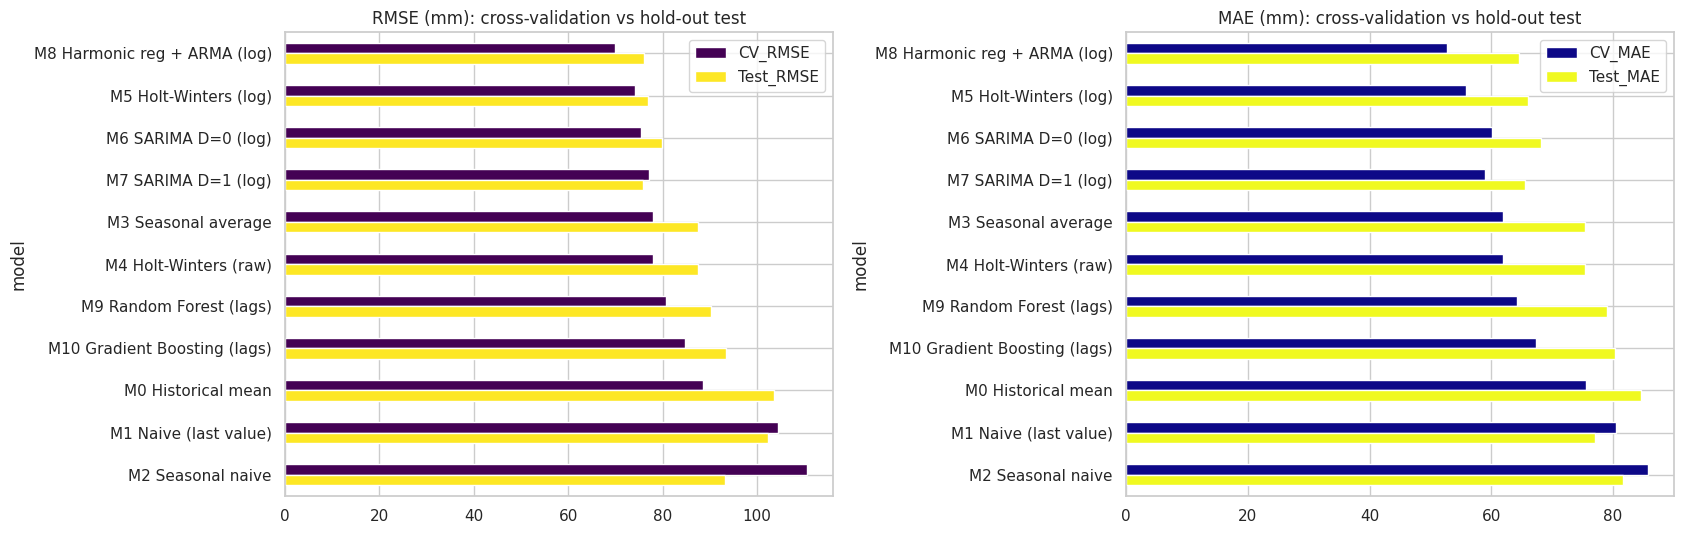

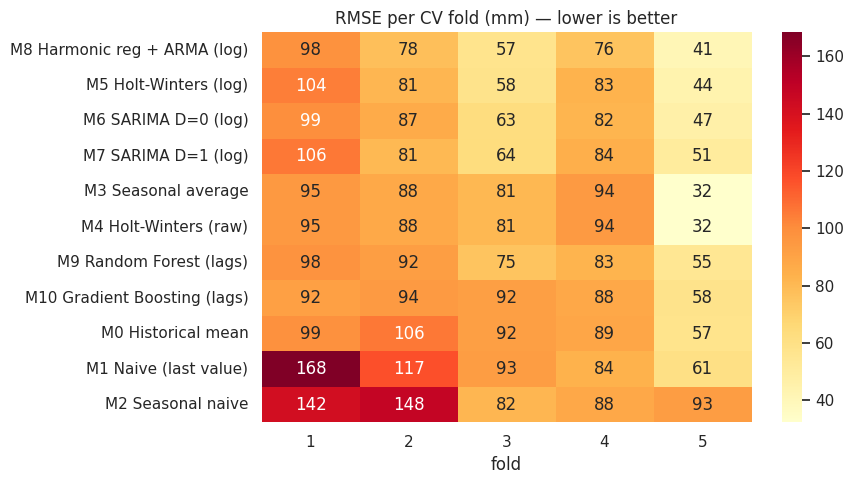

In [ ]:
rows = []
for n, r in RESULTS.items():
    cv, t = r["cv"], r["test"]
    rows.append({"model": n, "CV_MAE": cv.MAE.mean(), "CV_RMSE": cv.RMSE.mean(), "CV_RMSE_std": cv.RMSE.std(), "CV_MASE": cv.MASE.mean(),
                 "Test_MAE": t["MAE"], "Test_RMSE": t["RMSE"], "Test_MASE": t["MASE"], "Test_Bias": t["Bias"]})
comp = pd.DataFrame(rows).set_index("model")
base_cv = comp.loc["M3 Seasonal average", "CV_RMSE"]; base_te = comp.loc["M3 Seasonal average", "Test_RMSE"]
comp["Skill_vs_SeasAvg_CV(%)"]   = (1 - comp["CV_RMSE"] / base_cv) * 100
comp["Skill_vs_SeasAvg_Test(%)"] = (1 - comp["Test_RMSE"] / base_te) * 100
comp["CV_rank"] = comp["CV_RMSE"].rank().astype(int); comp["Test_rank"] = comp["Test_RMSE"].rank().astype(int)
comp = comp.sort_values("CV_RMSE")
display(comp.round(2).style.highlight_min(subset=["CV_MAE", "CV_RMSE", "CV_MASE", "Test_MAE", "Test_RMSE", "Test_MASE"], color="#c6efce")
                          .highlight_max(subset=["Skill_vs_SeasAvg_CV(%)", "Skill_vs_SeasAvg_Test(%)"], color="#c6efce"))

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
comp[["CV_RMSE", "Test_RMSE"]].plot(kind="barh", ax=ax[0], colormap="viridis"); ax[0].invert_yaxis(); ax[0].set_title("RMSE (mm): cross-validation vs hold-out test")
comp[["CV_MAE", "Test_MAE"]].plot(kind="barh", ax=ax[1], colormap="plasma");    ax[1].invert_yaxis(); ax[1].set_title("MAE (mm): cross-validation vs hold-out test")
plt.tight_layout(); plt.show()

# robustness: RMSE per CV fold
fold_rmse = pd.DataFrame({n: r["cv"]["RMSE"] for n, r in RESULTS.items()}).T.loc[comp.index]
plt.figure(figsize=(9, 5)); sns.heatmap(fold_rmse, annot=True, fmt=".0f", cmap="YlOrRd"); plt.title("RMSE per CV fold (mm) — lower is better"); plt.xlabel("fold"); plt.ylabel("")
plt.tight_layout(); plt.show()

### 💡 Insight
- **Ranking by CV RMSE:** M8 Harmonic (69.9) → M5 Holt-Winters-log (74.2) → M6 SARIMA D=0 (75.5) → M7 SARIMA D=1 (77.2) → M3 Seasonal average = M4 (77.9) → M9 RF (80.7) → M10 GBM (85.0) → M0 Mean (88.7) → M1 Naive (104.6) → M2 Seasonal naive (110.6).
- **Test RMSE agrees on the groups:** the four log-scale statistical models (M5–M8) are all at **75.8–79.9**, i.e. **9–13 % better than the seasonal average (87.5)**; the ML models and baselines are behind. M7 is nominally first on test (75.8) with M8 a close second (76.0) — a difference of 0.2 mm that is meaningless.
- Test errors are higher than CV errors for every model (e.g. M8: 76.0 vs 69.9). That is expected: the test years were unusually dry, and the horizon is 36 months instead of 12.
- The fold heat-map shows the **year matters more than the model**: RMSE swings by tens of mm between folds for the same model. Even the best model has MASE ≈ 0.48–0.60 and a typical error of ~52–65 mm on a ~176 mm average month — consistent with the ~59 % irreducible noise found in the STL decomposition.
- **Overall pattern:** (1) log transform + (2) smooth seasonality (3) with a little short-term memory beats everything else; heavier machinery (SARIMA's stochastic seasonality, RF/GBM) does not help.

## 9. Select the Best Model

🏆 BEST MODEL (by CV RMSE): M8 Harmonic reg + ARMA (log)
CV_MAE       52.66
CV_RMSE      69.94
CV_MASE       0.48
Test_MAE     64.49
Test_RMSE    76.05
Test_MASE     0.60
Test_Bias   -11.62

RMSE gain vs seasonal average per fold: [-3.3, 9.9, 23.7, 18.5, -9.0]  → better in 3 of 5 folds


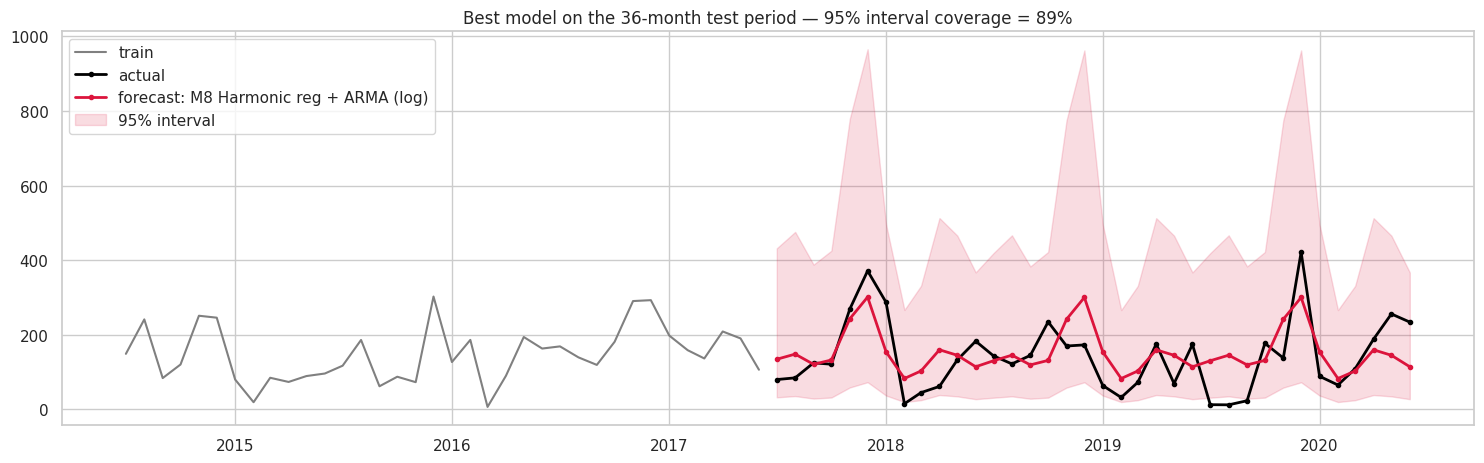

95% interval coverage on test = 89% (32/36 months) | median interval width = 415 mm
Forecast mean over test = 152 mm vs actual mean = 141 mm vs training mean = 179 mm


In [ ]:
# Selection rule: lowest cross-validated RMSE (RMSE punishes missing the heavy-rain months, which matter most).
# The hold-out test set is NOT used for selection.
best_name = comp["CV_RMSE"].idxmin()
best = RESULTS[best_name]
print("🏆 BEST MODEL (by CV RMSE):", best_name)
print(comp.loc[best_name, ["CV_MAE", "CV_RMSE", "CV_MASE", "Test_MAE", "Test_RMSE", "Test_MASE", "Test_Bias"]].round(2).to_string())

# Is the gain over the seasonal-average benchmark larger than fold-to-fold noise?
d = (RESULTS["M3 Seasonal average"]["cv"]["RMSE"] - best["cv"]["RMSE"])
print(f"\nRMSE gain vs seasonal average per fold: {d.round(1).tolist()}  → better in {(d > 0).sum()} of {len(d)} folds")

# Forecast vs actual on the test years, with 95% interval
f = best["forecast"]
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.plot(train.iloc[-36:], color="grey", label="train"); ax.plot(test, color="black", lw=2, marker="o", ms=3, label="actual")
ax.plot(f.index, f["forecast"], color="crimson", lw=2, marker="o", ms=3, label=f"forecast: {best_name}")
ax.fill_between(f.index, f["lower"], f["upper"], color="crimson", alpha=.15, label="95% interval")
cover = ((test.values >= f["lower"].values) & (test.values <= f["upper"].values)).mean()
ax.set_title(f"Best model on the 36-month test period — 95% interval coverage = {cover:.0%}"); ax.legend(); plt.tight_layout(); plt.show()
print(f"95% interval coverage on test = {cover:.0%} ({int(cover*len(test))}/{len(test)} months) | median interval width = {(f['upper']-f['lower']).median():.0f} mm")
print(f"Forecast mean over test = {f['forecast'].mean():.0f} mm vs actual mean = {test.mean():.0f} mm vs training mean = {train.mean():.0f} mm")

### 💡 Insight
- **Selected model: M8 — Harmonic regression (K = 3) with ARMA(1,1) errors on log(1+rainfall).** Selection used **cross-validation only** (CV RMSE 69.9); the test set was not used to choose. It also scores well on the untouched test set (RMSE 76.0, MAE 64.5, MASE 0.60), a **13 % RMSE gain over the seasonal-average benchmark**.
- **Honest caveat:** per fold, the RMSE gain over the seasonal average is `[−3.3, +9.9, +23.7, +18.5, −9.0]` mm — better in **3 of 5 folds**, with an average of +8 mm against fold-to-fold noise of about 21 mm. The CV margin alone is therefore not statistically conclusive; the confidence comes from the *agreement* between CV, the test set, the AIC comparison and the consistent advantage of the whole log-scale family. If simplicity is preferred, M5 (Holt-Winters-log) is a near-equivalent, simpler alternative.
- **Interval check:** the 95 % prediction interval covered **89 % of the test months (32 of 36)** — slightly below the nominal 95 %. All four misses were extreme-dry months (Feb 2018: 14.8 mm; Jul–Sep 2019: 11.8–22.8 mm) that the model considered possible but very unlikely. The interval is wide (median width ≈ 415 mm) because single-month rainfall is intrinsically very variable.
- Average forecast over the test period was 152 mm vs 141 mm actual (training mean 179 mm): the model partly adapts to the drier years but still over-forecasts by ~11 mm.

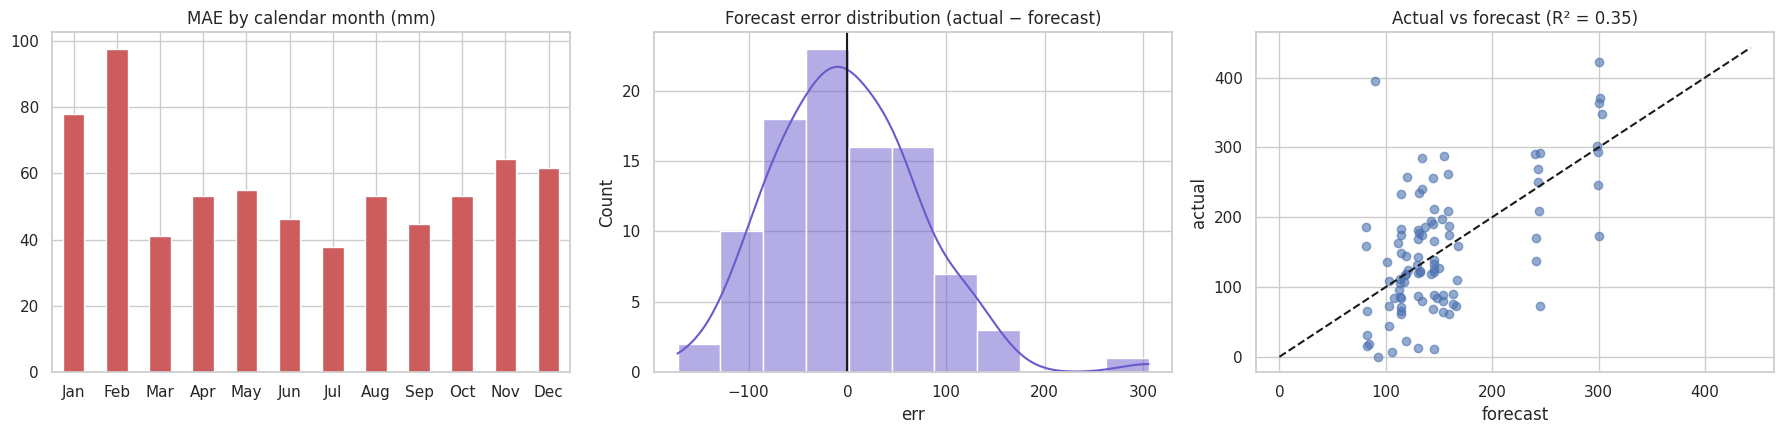

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
MAE,77.7,97.6,41.2,53.0,54.8,46.1,37.8,53.2,44.6,53.2,64.4,61.4
bias,-7.4,24.1,-30.9,-29.5,13.7,28.9,-5.6,-9.2,-2.8,34.6,-31.5,14.5
mean_actual,147.5,108.8,75.5,133.1,158.4,142.2,121.8,133.5,115.0,166.0,211.2,314.7


In [ ]:
# Where does the best model make its largest errors? (all 96 out-of-sample forecasts: 60 CV + 36 test)
oos = best["oos"].copy(); oos["err"] = oos.actual - oos.pred; oos["abs_err"] = oos.err.abs(); oos["cal_month"] = oos.index.month
by_m = oos.groupby("cal_month").agg(MAE=("abs_err", "mean"), bias=("err", "mean"), mean_actual=("actual", "mean"))
by_m.index = month_names

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
by_m["MAE"].plot(kind="bar", ax=ax[0], color="indianred", rot=0); ax[0].set_title("MAE by calendar month (mm)")
sns.histplot(oos.err, kde=True, ax=ax[1], color="slateblue"); ax[1].axvline(0, color="k"); ax[1].set_title("Forecast error distribution (actual − forecast)")
ax[2].scatter(oos.pred, oos.actual, alpha=.6); lim = [0, max(oos.actual.max(), oos.pred.max()) * 1.05]
ax[2].plot(lim, lim, "k--"); ax[2].set_xlabel("forecast"); ax[2].set_ylabel("actual"); ax[2].set_title(f"Actual vs forecast (R² = {np.corrcoef(oos.pred, oos.actual)[0,1]**2:.2f})")
plt.tight_layout(); plt.show()
display(by_m.round(1).T)

### 💡 Insight
- **Errors are largest in the high-variance months:** MAE is highest in **February (97.6 mm)** and **January (77.7 mm)**, then November (64.4) and December (61.5); it is lowest in **July (37.8)** and March (41.2). This matches the EDA: February has a coefficient of variation of about 1.0 — dry on average, but occasionally hit by big events.
- The monthly bias values swing between roughly −31 and +35 mm with no consistent sign pattern, and each calendar month has only **8** out-of-sample forecasts — so this is sampling noise rather than a systematic seasonal bias that could be corrected.
- Actual-vs-forecast **R² ≈ 0.35** on all 96 out-of-sample points (≈ 0.39 on test only): the model explains roughly a third of the month-to-month variance — a solid result given that about 59 % of the variance is irreducible noise. The error histogram is centred near zero (mean −0.1 mm, median −7 mm) but **right-skewed (skew 0.72)**: the biggest misses are wetter-than-forecast months (up to +305 mm), while the model over-forecasts by at most about 170 mm. About 17 % of forecasts miss by more than 100 mm.

## 10. Final Model: Re-fit on ALL Data and Forecast the Future

,forecast,lower,upper
month,,,
2020-07-01,143.4,26.1,469.1
2020-08-01,147.2,26.8,481.3
2020-09-01,121.5,22.0,397.7
2020-10-01,136.9,24.9,448.0
2020-11-01,248.3,45.8,810.6
2020-12-01,299.2,55.3,976.2
2021-01-01,150.6,27.4,492.5
2021-02-01,79.1,14.0,259.8
2021-03-01,97.7,17.5,320.3


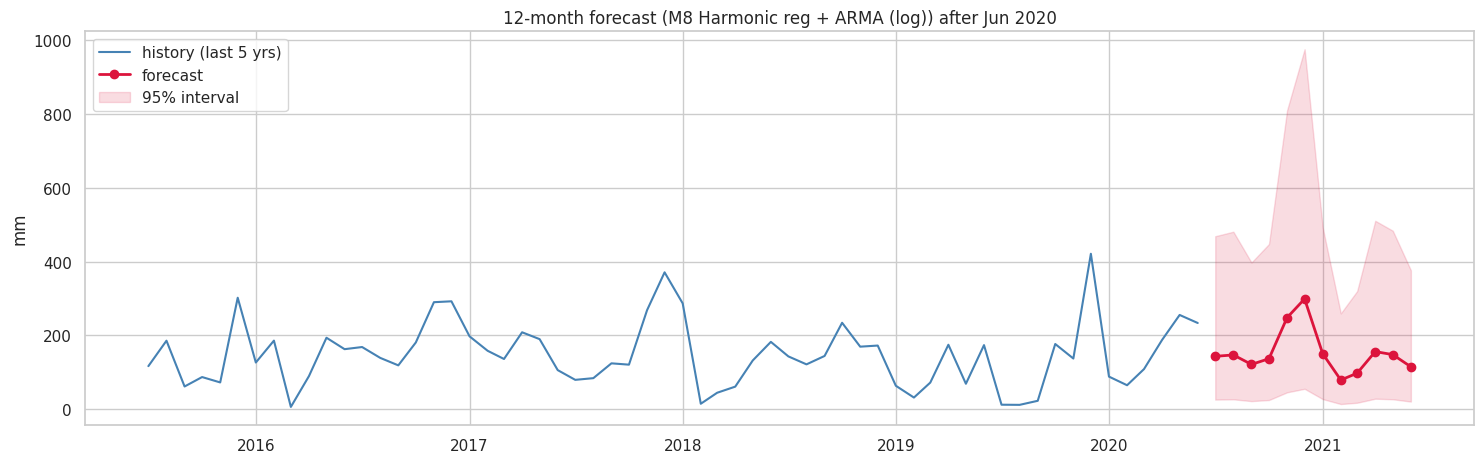

Forecast total for the next 12 months: 1843 mm  (historical average annual total ≈ 2118 mm)


In [ ]:
FUTURE_H = 12
final_model = FACTORIES[best_name]().fit(y)                  # train + test = all 462 months
final_model.set_error_quantiles(best["errs"])                # empirical fallback for non-native intervals
future = final_model.predict(FUTURE_H)
future.index.name = "month"
display(future.round(1))

fig, ax = plt.subplots(figsize=(15, 4.8))
ax.plot(y.iloc[-60:], color="steelblue", label="history (last 5 yrs)")
ax.plot(future.index, future["forecast"], color="crimson", marker="o", lw=2, label="forecast")
ax.fill_between(future.index, future["lower"], future["upper"], color="crimson", alpha=.15, label="95% interval")
ax.set_title(f"{FUTURE_H}-month forecast ({best_name}) after {y.index[-1]:%b %Y}"); ax.set_ylabel("mm"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Forecast total for the next {FUTURE_H} months: {future.forecast.sum():.0f} mm  (historical average annual total ≈ {annual.mean():.0f} mm)")

### 💡 Insight
- Forecast for **Jul 2020 → Jun 2021**: a pronounced wet season (**Dec ≈ 299 mm, Nov ≈ 248 mm**) and a dry trough in **Feb ≈ 79 mm**, matching the climatology found in the EDA.
- The 12-month total is **≈ 1 843 mm vs 2 118 mm for the historical annual average (−13 %)**. Two honest reasons: (1) back-transforming from the log scale gives a *median-type* forecast (typical month), and the sum of monthly medians is lower than the sum of means; (2) the model reflects the drier recent years. We tested a bias-correction ("smearing") adjustment in development: it made cross-validated accuracy **worse** (CV RMSE 69.9 → 76.7), so it was not adopted — use the totals as a typical-case planning figure, not an expected mean.
- Intervals are wide (e.g. Dec: 55–976 mm) because individual months are very variable; for operational use, the *shape* (which months are likely wet/dry) is more reliable than any single month's value.
- The dataset ends in June 2020, so this forecast window is now in the past: you can check it against NEA's published figures as an extra out-of-time validation.

## 11. Save the Best Model

In [ ]:
SAVE_DIR = pathlib.Path("saved_model"); SAVE_DIR.mkdir(exist_ok=True)

artifact = {"model": final_model, "name": best_name, "trained_until": str(y.index[-1].date()), "unit": "mm", "target": "monthly total rainfall"}
joblib.dump(artifact, SAVE_DIR / "best_rainfall_forecaster.joblib")

meta = {
    "best_model": best_name,
    "selection_rule": "lowest cross-validated RMSE (5 expanding-window folds x 12-month horizon on training data)",
    "data": {"station": "Changi Climate Station", "from": str(y.index[0].date()), "to": str(y.index[-1].date()), "n_months": int(len(y))},
    "validation": comp.loc[best_name, ["CV_MAE", "CV_RMSE", "CV_MASE", "Test_MAE", "Test_RMSE", "Test_MASE"]].round(3).to_dict(),
    "usage": "from rain_forecasters import *; import joblib; m = joblib.load(path)['model']; m.predict(12)",
}
json.dump(meta, open(SAVE_DIR / "model_card.json", "w"), indent=2)
comp.round(3).to_csv(SAVE_DIR / "model_comparison.csv")
future.round(2).to_csv(SAVE_DIR / "forecast_next_12_months.csv")
for p in sorted(SAVE_DIR.iterdir()):
    print(f"{p}  ({p.stat().st_size / 1e3:.1f} KB)")

saved_model/best_rainfall_forecaster.joblib  (1101.0 KB)
saved_model/forecast_next_12_months.csv  (0.4 KB)
saved_model/model_card.json  (0.6 KB)
saved_model/model_comparison.csv  (1.2 KB)


### 💡 Insight
- The saved `.joblib` (≈ 1 MB) contains the fitted model, trained on **all 462 months**, plus its name and training end-date. `model_card.json` records the selection rule and validation scores; `model_comparison.csv` is the audit trail for why this model was chosen; the forecast CSV holds the next 12 months.
- To load the artifact elsewhere you must keep **`rain_forecasters.py`** next to it (pickle stores classes by reference).

## 12. Reload the Model & Forecast (deployment check)

In [ ]:
loaded = joblib.load(SAVE_DIR / "best_rainfall_forecaster.joblib")
print("Loaded:", loaded["name"], "| trained until", loaded["trained_until"])

def forecast_rainfall(path=SAVE_DIR / "best_rainfall_forecaster.joblib", months=12):
    a = joblib.load(path)
    out = a["model"].predict(months).round(1)
    out.index = out.index.strftime("%Y-%m")
    return out

reloaded_fc = forecast_rainfall(months=FUTURE_H)
same = np.allclose(reloaded_fc["forecast"].values, future["forecast"].round(1).values)
print("Reloaded model reproduces the in-memory forecast:", same)
display(forecast_rainfall(months=6))

Loaded: M8 Harmonic reg + ARMA (log) | trained until 2020-06-01
Reloaded model reproduces the in-memory forecast: True


,forecast,lower,upper
2020-07,143.4,26.1,469.1
2020-08,147.2,26.8,481.3
2020-09,121.5,22.0,397.7
2020-10,136.9,24.9,448.0
2020-11,248.3,45.8,810.6
2020-12,299.2,55.3,976.2


### 💡 Insight
- The reloaded model reproduces the in-memory forecast exactly (**`True`**), so the saved artifact is complete and `forecast_rainfall(months=n)` can be wrapped in an API / scheduled job for monthly rainfall outlooks.
- For production: re-train as new monthly data arrives (the model is fast: ~1 s to fit), and keep monitoring the error against the seasonal-average benchmark — if the gain disappears, fall back to the simpler model.

## 13. Conclusion & Next Steps

**What we did**
1. **Data audit & EDA** on 462 months of Changi rainfall: clean data, strongly seasonal (Dec 318 mm vs Feb 105 mm), stationary, no significant trend, weak short-term memory, and ~59 % of variance that is irreducible noise.
2. **Leak-free validation:** chronological split (last 36 months as test) + 5-fold rolling-origin CV with a 12-month horizon.
3. **Eleven models, each motivated by the weakness of the previous one**

| Stage | Model | CV RMSE (mm) | Test RMSE (mm) | Verdict |
|---|---|---|---|---|
| Baseline | M0 Historical mean | 88.7 | 103.7 | benchmark |
| Baseline | M1 Naive / M2 Seasonal naive | 104.6 / 110.6 | 102.3 / 93.3 | worse than the mean — one noisy value is a bad forecast |
| Baseline | M3 Seasonal average | 77.9 | 87.5 | the real benchmark |
| Smoothing | M4 Holt-Winters raw / M5 log | 77.9 / 74.2 | 87.5 / 77.0 | log transform gives the first real gain |
| ARIMA | M6 SARIMA D=0 / M7 D=1 | 75.5 / 77.2 | 79.9 / 75.8 | no gain over M5; residual autocorrelation left |
| Harmonic | **M8 Fourier K=3 + ARMA(1,1), log** | **69.9** | **76.0** | **best CV; −13 % vs benchmark on test** |
| ML | M9 Random Forest / M10 Gradient Boosting | 80.7 / 85.0 | 90.4 / 93.1 | not better than the seasonal average |

4. **Best model selected on CV only, evaluated once on test, re-fitted on all data, saved** (`saved_model/`), reloaded and verified.

**Key lessons**
- With noisy, weakly autocorrelated data, **a transformation (log) + a smooth seasonal curve + a little ARMA** beats both elaborate stochastic seasonality (SARIMA) and flexible ML.
- Expect modest accuracy: typical error ≈ 52–65 mm on a ~176 mm month (R² ≈ 0.35). Differences between the top four models are small relative to the year-to-year noise.
- Intervals cover 89 % of test months (nominal 95 %); extreme-dry months are the main miss.

**Possible improvements**
- Add **climate drivers** known in advance or forecastable (e.g. ENSO / Indian Ocean Dipole indices, monsoon-phase indicators) — the single most promising way to beat the noise ceiling.
- Season-specific prediction intervals (heteroscedastic by month) and quantile / probabilistic models; Box-Cox or Tweedie-type models for the skewed target.
- Daily data and **ensembles** (e.g. averaging M5 + M7 + M8) to reduce variance; a neural sequence model (LSTM / N-BEATS) once more data is available.
- Operationally: monthly re-training, monitoring against the seasonal-average benchmark, and a simple API around `forecast_rainfall()`.